# PROBLEMA 4: ¿Quieres saber cuánto vale tu coche?
Autor: Jesús Peñaranda Ibarz

El objetivo es predecir el precio de venta (`Price`) de un coche usado a partir de sus características (fabricante, modelo, estado, costes etc...):

- a) División train/test, tratamiento de categóricas, imputación con `KNNImputer` y PCA.
- b) Transformación de variables y regresión lineal (calidad, pesos y residuos).
- c) Regresión Ridge y LASSO: comparación de pesos y selección de variables.
- d) Interacciones con `PolynomialFeatures` (grado 2) y nuevo ajuste de Ridge y LASSO.

## Descripción de las variables

| Variable | Qué es | Tipo |
|---|---|---|
| Manufacturer | Marca del coche (Toyota, Ford, VW, BMW, Porsche) | Categórica nominal |
| Model | Modelo del coche (RAV4, Focus, Golf...). Anidada en `Manufacturer` | Categórica nominal |
| Engine size | Tamaño del motor en litros | Numérica |
| Fuel type | Tipo de combustible (gasolina, diésel, híbrido) | Categórica nominal |
| Year of manufacture | Año de fabricación | Numérica |
| Mileage | Kilómetros recorridos | Numérica |
| Price | Precio de venta (variable objetivo) | Numérica |
| Inspection rating | Puntuación de la inspección técnica (casi siempre 10) | Numérica |
| Tires quality | Estado de los neumáticos (0-10) | Numérica |
| Interior condition | Estado del interior (0-10) | Numérica |
| Comfort level | Nivel de confort (0-10) | Numérica |
| Sound system quality | Calidad del equipo de sonido (0-10) | Numérica |
| Model reviews score | Valoración del modelo en reseñas (0-10) | Numérica |
| Overall rating | Valoración general del coche (0-10) | Numérica |
| Independent rating | Valoración de una fuente independiente (0-10) | Numérica |
| Insurance cost | Coste del seguro (solo toma los valores 200 o 800) | Categórica binaria |
| Maintenance cost | Coste de mantenimiento | Numérica |

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score, cross_val_predict
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error
from apafib import load_car_sales

sns.set_theme(style="whitegrid")

In [2]:
df = load_car_sales()
print(df.shape)
df.head()

(750, 17)


,Manufacturer,Model,Engine size,Fuel type,Year of manufacture,Mileage,Price,Inspection rating,Tires quality,Interior condition,Comfort level,Sound system quality,Model reviews score,Overall rating,Independent rating,Insurance cost,Maintenance cost
0,Toyota,RAV4,2.4,Hybrid,2020.0,21317.0,68597,10.0,7.6,8.8,7.0,8.2,7.8,8.2,10.0,800.0,300.0000
1,Ford,Focus,1.8,Petrol,2018.0,22500.0,35276,10.0,7.6,7.3,5.3,4.4,5.5,5.9,6.6,800.0,127.9000
2,Ford,Mondeo,1.6,Diesel,2013.0,79521.0,17370,10.0,8.0,7.6,5.9,4.3,3.9,6.2,6.2,800.0,123.3054
3,Toyota,Yaris,1.2,Petrol,2003.0,159534.0,3213,10.0,7.5,5.4,6.5,7.9,NaN,7.7,NaN,800.0,131.0276
4,Ford,Mondeo,1.4,Diesel,2000.0,126511.0,4832,10.0,8.0,5.4,4.9,4.9,NaN,5.5,7.1,800.0,100.0000


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 750 entries, 0 to 749
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   Manufacturer          750 non-null    category
 1   Model                 750 non-null    category
 2   Engine size           729 non-null    float64 
 3   Fuel type             750 non-null    category
 4   Year of manufacture   696 non-null    float64 
 5   Mileage               723 non-null    float64 
 6   Price                 750 non-null    int64   
 7   Inspection rating     745 non-null    float64 
 8   Tires quality         746 non-null    float64 
 9   Interior condition    742 non-null    float64 
 10  Comfort level         703 non-null    float64 
 11  Sound system quality  717 non-null    float64 
 12  Model reviews score   695 non-null    float64 
 13  Overall rating        723 non-null    float64 
 14  Independent rating    716 non-null    float64 
 15  Insurance cost   

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Engine size,729.0,1.74,0.69,1.0,1.40,1.60,2.00,5.0
Year of manufacture,696.0,2004.40,9.85,1984.0,1996.00,2004.00,2013.00,2022.0
Mileage,723.0,111412.10,68463.27,1197.0,57047.00,101169.00,155044.00,405205.0
Price,750.0,13472.03,15430.64,133.0,3011.25,8039.00,19422.75,131460.0
Inspection rating,745.0,9.98,0.37,1.0,10.00,10.00,10.00,10.0
Tires quality,746.0,7.77,0.59,1.0,7.50,7.80,8.10,9.3
Interior condition,742.0,6.30,0.81,1.0,5.80,6.20,6.80,8.9
Comfort level,703.0,5.55,0.68,1.0,5.10,5.60,6.00,7.9
Sound system quality,717.0,6.36,1.55,1.0,4.90,6.60,7.70,9.5
Model reviews score,695.0,6.18,0.94,1.0,5.50,6.20,6.90,8.4


# a) Preprocesado y PCA

## División en entrenamiento y test (70% / 30%)

Separamos la variable objetivo (`Price`) y dividimos el conjunto antes de cualquier análisis o transformación. Así, todo lo que aprendamos de los datos se calcula solo con entrenamiento y se aplica después al test, evitando la fuga de información. Fijo `random_state` para que el resultado sea reproducible.

In [5]:
X = df.drop(columns="Price")
Y = df["Price"]
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=1234)
print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")

Train: (525, 16)  |  Test: (225, 16)


## Criterio de evaluación (el mismo en todo el notebook)

Antes de preprocesar fijo un único criterio para todos los apartados: el MAE en euros (error absoluto medio del precio). Es interpretable y más robusto que el RMSE frente a los pocos coches muy caros. Los modelos que se entrenen con `log(Price)` deshacen la transformación (`TransformedTargetRegressor`), así que también predicen y se evalúan en euros y todos son comparables.

- El error de generalización de cada modelo es el de validación cruzada sobre train (10 folds, siempre las mismas particiones `cv`): la media de la distribución de los 10 MAE, junto con su desviación. Es el error medio esperado con datos nuevos, y es el único que uso para ajustar hiperparámetros y para escoger entre modelos.
- El error de test solo sirve para detectar problemas, sobre todo sobreajuste: debería caer dentro de la distribución de errores de validación cruzada. Lo compruebo con su posición respecto a esa distribución (`z test` = desviaciones típicas que se aleja de la media de CV).
- El error sobre train no se calcula: el modelo ya ha visto esos datos y no dice nada de su capacidad de generalización.

In [6]:
CRITERIO = "neg_mean_absolute_error"   # sklearn maximiza las puntuaciones: el MAE va con signo negativo
cv = KFold(n_splits=10, shuffle=True, random_state=1234)

## Valores perdidos y variables sin información

In [7]:
pd.DataFrame({"NaN train": X_train.isna().sum(), "NaN test": X_test.isna().sum(), "% train": (X_train.isna().mean()*100).round(1)})

,NaN train,NaN test,% train
Manufacturer,0,0,0.0
Model,0,0,0.0
Engine size,19,2,3.6
Fuel type,0,0,0.0
Year of manufacture,35,19,6.7
Mileage,20,7,3.8
Inspection rating,4,1,0.8
Tires quality,3,1,0.6
Interior condition,6,2,1.1
Comfort level,36,11,6.9


In [8]:
X_train["Inspection rating"].value_counts(dropna=False)

Inspection rating
10.0    519
NaN       4
5.8       1
9.7       1
Name: count, dtype: int64

Hay valores perdidos en casi todas las variables continuas (y en `Insurance cost`), pero en una proporción pequeña (< 8%), así que procederé a imputarlos en vez de eliminar filas.
`Inspection rating` vale 10 en la práctica totalidad de los coches (varianza casi nula), así que no aporta información para distinguir precios y la eliminaré del dataset.

In [9]:
X_train = X_train.drop(columns="Inspection rating")
X_test = X_test.drop(columns="Inspection rating")

## Tratamiento de las variables categóricas

Analizaré el significado de cada variable categórica para decidir cómo codificarla o transformarla.

In [10]:
categoricas = ["Manufacturer", "Model", "Fuel type", "Insurance cost"]
display(X_train[categoricas].nunique())
pd.crosstab(X_train["Model"], X_train["Manufacturer"])

Manufacturer       5
Model             15
Fuel type          3
Insurance cost     2
dtype: int64

Manufacturer,BMW,Ford,Porsche,Toyota,VW
Model,,,,,
718 Cayman,0,0,6,0,0
911,0,0,5,0,0
Cayenne,0,0,11,0,0
Fiesta,0,48,0,0,0
Focus,0,52,0,0,0
Golf,0,0,0,0,53
M5,14,0,0,0,0
Mondeo,0,49,0,0,0
Passat,0,0,0,0,50


De la tabla cruzada se sacan las decisiones de codificación:

- `Insurance cost` solo toma dos valores, es en realidad una variable binaria (seguro barato / caro), así que la recodificamos a binaria (0/1)
- `Fuel type` es nominal sin orden (diésel, gasolina, híbrido): aplicamos one-hot encoding
- `Model` está anidada en `Manufacturer`: cada modelo pertenece a una sola marca (en la tabla, cada fila tiene un único valor distinto de cero). Un Fiesta es siempre un Ford, un Golf siempre un VW, un 911 siempre un Porsche etc... Si conocemos el modelo, podremos deducir la marca más tarde, así que `Manufacturer` no aporta información que no esté ya en `Model`

Eliminamos `Manufacturer` y codificamos solo `Model` (one-hot-encoding). Así no perdemos nada, la información de la marca sigue estando dentro del modelo.

In [11]:
marca_y_modelo = pd.get_dummies(X_train[["Manufacturer", "Model"]], drop_first=True, dtype=float)
marca_y_modelo.insert(0, "intercepto", 1.0)
print(f"Marca + modelo: {marca_y_modelo.shape[1]} columnas, rango = {np.linalg.matrix_rank(marca_y_modelo.values)}")

solo_modelo = pd.get_dummies(X_train["Model"], prefix="Model", drop_first=True, dtype=float)
solo_modelo.insert(0, "intercepto", 1.0)
print(f"Solo modelo:    {solo_modelo.shape[1]} columnas, rango = {np.linalg.matrix_rank(solo_modelo.values)}")

def codificar(datos):
    datos = datos.copy()
    datos["Insurance cost"] = datos["Insurance cost"].replace({200.0: 0, 800.0: 1})
    modelo = pd.get_dummies(datos["Model"], prefix="Model", drop_first=True, dtype=float)
    combustible = pd.get_dummies(datos["Fuel type"], prefix="Fuel type", drop_first=True, dtype=float)
    return pd.concat([datos.drop(columns=["Manufacturer", "Model", "Fuel type"]), modelo, combustible], axis=1)

Marca + modelo: 19 columnas, rango = 15
Solo modelo:    15 columnas, rango = 15


Con marca + modelo la matriz tiene 19 columnas (con el intercepto) pero solo rango 15: sobran 4 columnas, que son las dummies de las marcas Ford, Toyota y VW y la de BMW, implícita en el intercepto. Cada una se puede obtener sumando las dummies de sus modelos. Con solo el modelo tenemos 15 columnas y rango 15 (rango completo): contiene exactamente la misma información, sin redundancia.

## Distribución de las variables y outliers

Guardamos una copia de train con las variables originales y el precio para explorarlas antes de codificar.

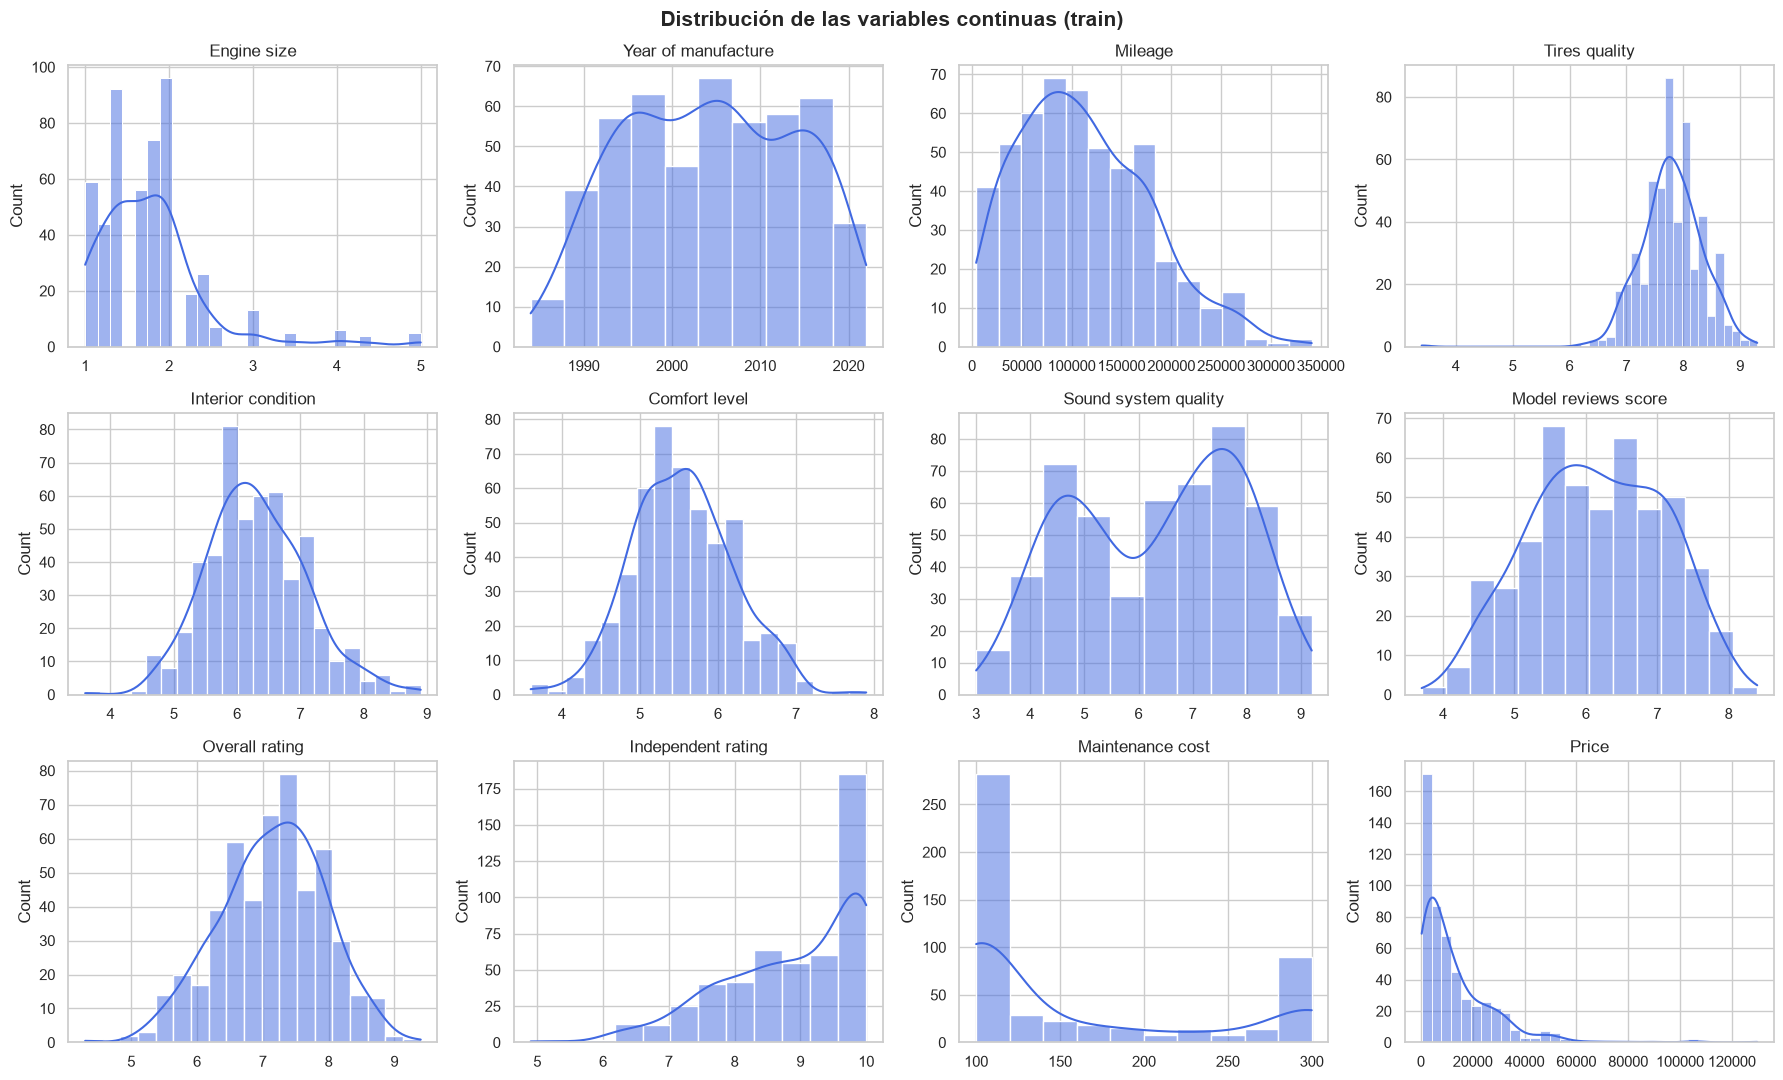

In [12]:
cont = ["Engine size", "Year of manufacture", "Mileage", "Tires quality", "Interior condition", "Comfort level", "Sound system quality", "Model reviews score", "Overall rating", "Independent rating", "Maintenance cost"]

train_eda = X_train.copy()
train_eda["Price"] = Y_train

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, var in zip(axes.flatten(), cont + ["Price"]):
    sns.histplot(train_eda[var].dropna(), kde=True, ax=ax, color="royalblue")
    ax.set_title(var)
    ax.set_xlabel("")
plt.suptitle("Distribución de las variables continuas (train)", fontweight="bold", fontsize=15)
plt.tight_layout()
plt.show()

Observaciones:
- `Price` tiene una asimetría muy fuerte a la derecha: la mayoría de coches valen menos de 20.000 €, pero hay unos pocos por encima de 100.000 €
- `Mileage` también es asimétrica a la derecha
- `Year of manufacture` es bastante uniforme entre 1990 y 2020
- `Engine size` es discreta (1.0, 1.2, 1.4... litros) con una cola larga de motores grandes (BMW M5, Porsche)
- Las valoraciones `Tires quality`, `Interior condition`, `Comfort level`, `Model reviews score` y `Overall rating` tienen forma de campana
- `Sound system quality` es bimodal (picos en 4.5 y 7.5): parece depender del tipo de coche o de la marca
- `Independent rating` está acumulada en 10
- `Maintenance cost` está acotada entre 100 y 300, con muchos coches justo en los extremos

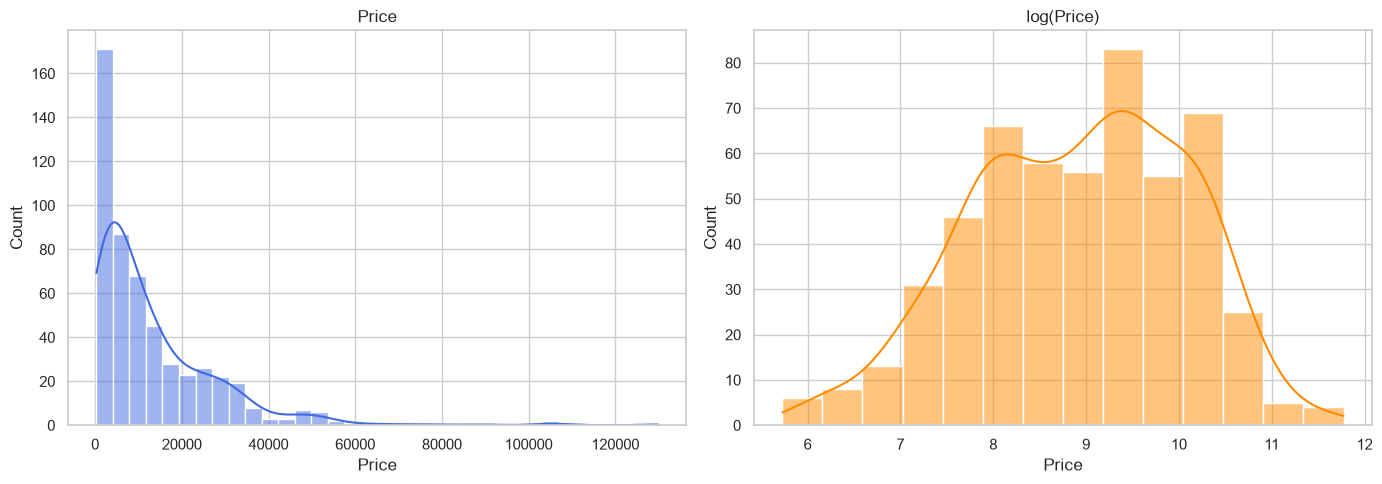

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(train_eda["Price"], kde=True, ax=axes[0], color="royalblue")
axes[0].set_title("Price")
sns.histplot(np.log(train_eda["Price"]), kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("log(Price)")
plt.tight_layout()
plt.show()

Al aplicar el logaritmo, el precio pasa de una distribución muy asimétrica a una forma mucho más simétrica y acampanada. Se acerca a una log-normal (no de manera exacta): el precio se forma multiplicando factores (marca\*antigüedad\*km etc...), no sumándolos. Se aprecian dos ligeros picos (8 y 9.5), que corresponden a la mezcla de gamas, modelos baratos y gama alta. Usaré esta transformación en el apartado b).

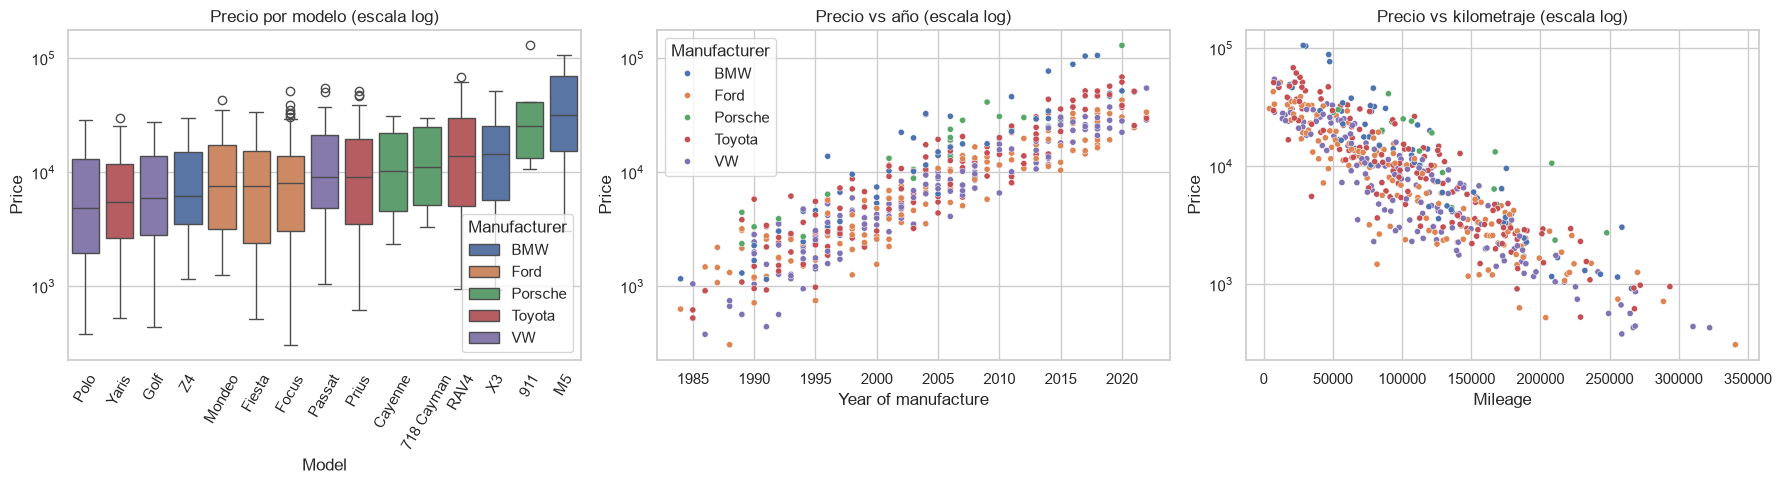

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
orden = train_eda.groupby("Model", observed=True)["Price"].median().sort_values().index
sns.boxplot(data=train_eda, x="Model", y="Price", order=orden, hue="Manufacturer", dodge=False, ax=axes[0])
axes[0].set_yscale("log")
axes[0].tick_params(axis="x", rotation=60)
axes[0].set_title("Precio por modelo (escala log)")
sns.scatterplot(data=train_eda, x="Year of manufacture", y="Price", hue="Manufacturer", ax=axes[1], s=20)
axes[1].set_yscale("log")
axes[1].set_title("Precio vs año (escala log)")
sns.scatterplot(data=train_eda, x="Mileage", y="Price", hue="Manufacturer", ax=axes[2], s=20, legend=False)
axes[2].set_yscale("log")
axes[2].set_title("Precio vs kilometraje (escala log)")
plt.tight_layout()
plt.show()

In [15]:
medianas = train_eda.groupby("Model", observed=True)["Price"].median().sort_values()
display(medianas)
print(f"911 / Polo: {medianas["911"] / medianas["Polo"]:.1f} veces")
print(f"M5  / Polo: {medianas["M5"]  / medianas["Polo"]:.1f} veces")

Model
Polo           4874.0
Yaris          5511.0
Golf           6006.0
Z4             6232.0
Mondeo         7577.0
Fiesta         7599.5
Focus          8039.5
Passat         9085.0
Prius          9136.5
Cayenne       10188.0
718 Cayman    11167.5
RAV4          13851.5
X3            14590.0
911           25261.0
M5            31584.5
Name: Price, dtype: float64

911 / Polo: 5.2 veces
M5  / Polo: 6.5 veces


- Precio por modelo: hay diferencias claras entre modelos (el M5 y el 911 cuestan de mediana unas 6 veces más que un Polo), pero dentro de cada modelo la dispersión es enorme (dos órdenes de magnitud). Por lo tanto, el modelo concreto no basta: el estado del coche es decisivo.
- Precio vs año: en escala logarítmica la relación es casi una recta. Esto quiere decir que el coche pierde aproximadamente el mismo porcentaje de valor cada año. En escala original esta relación sería una curva exponencial, que una regresión lineal no puede capturar.
- Precio vs kilometraje: también es aproximadamente lineal en escala logarítmica y decreciente.

Las marcas se separan verticalmente (BMW y Porsche por arriba, Ford y VW por debajo) con una pendiente parecida.

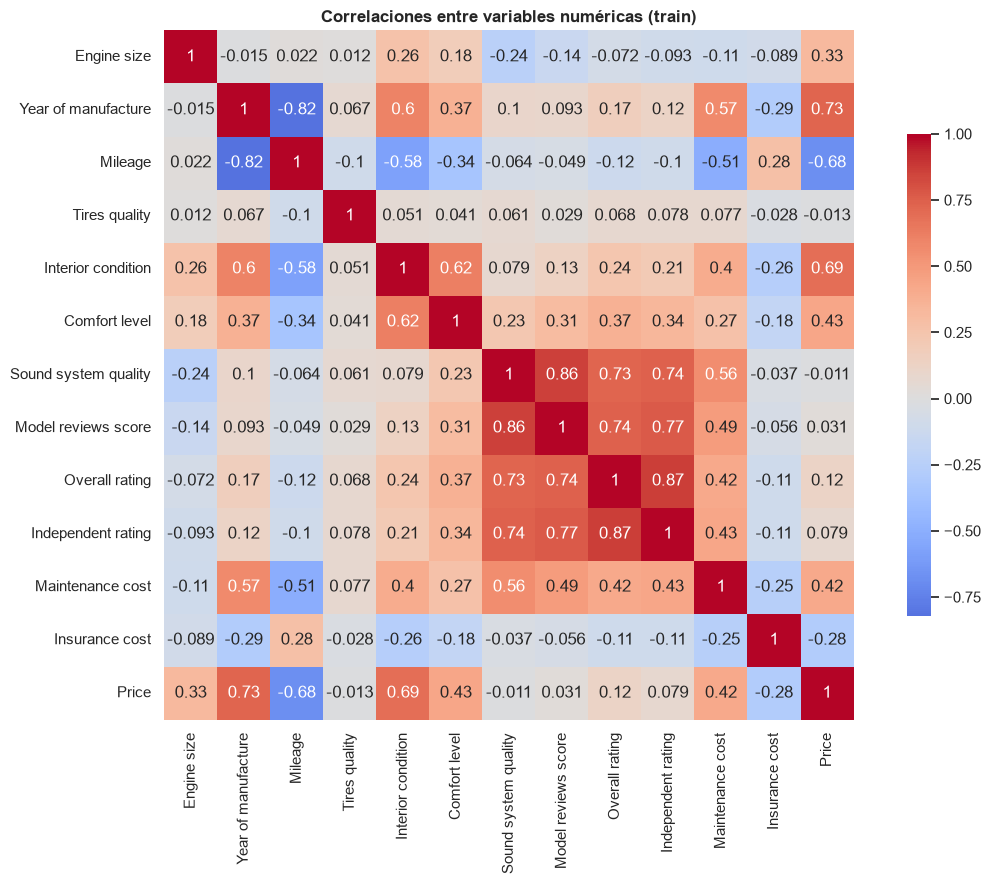

In [16]:
plt.figure(figsize=(12, 9))
corr = train_eda[cont + ["Insurance cost", "Price"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.7})
plt.title("Correlaciones entre variables numéricas (train)", fontweight="bold")
plt.tight_layout()
plt.show()

- Las variables más correlacionadas con el precio son `Year of manufacture` (0.73), `Interior condition` (0.69) y `Mileage` (-0.68)
- `Year` y `Mileage` están muy correlacionadas entre sí (-0.82): los coches más viejos tienen más kilómetros. `Interior condition` también depende de la antigüedad (0.60 con el año y -0.58 con el kilometraje). Su correlación con el precio puede ser en gran parte indirecta, a través de la antigüedad.
- Hay un bloque de valoraciones muy correlacionadas entre sí (`Sound system quality`, `Model reviews score`, `Overall rating`, `Independent rating`, entre 0.73 y 0.87) que, sin embargo, casi no tiene relación con el precio (< 0.12). Este bloque es redundante y, previsiblemente, poco útil para predecir
- `Tires quality` no está correlacionada con nada.

Esta colinealidad podría afectar a la interpretación de los pesos de la regresión lineal. Lo comprobaré en el apartado c) comparando con Ridge y LASSO.

### Outliers

Las valoraciones (`Tires quality`, `Interior condition`, `Comfort level`, `Model reviews score`, `Overall rating`) tienen forma aproximadamente normal (lo comprobamos con el Q-Q plot de cada una). Para tratar los outliers utilizaré la regla de las 3 desviaciones típicas. Debido a que la regresión lineal es sensible a outliers los eliminaré con esta regla.

Solo filtraré las filas de train, el test debe representar datos reales tal cual nos llegarían al modelo.

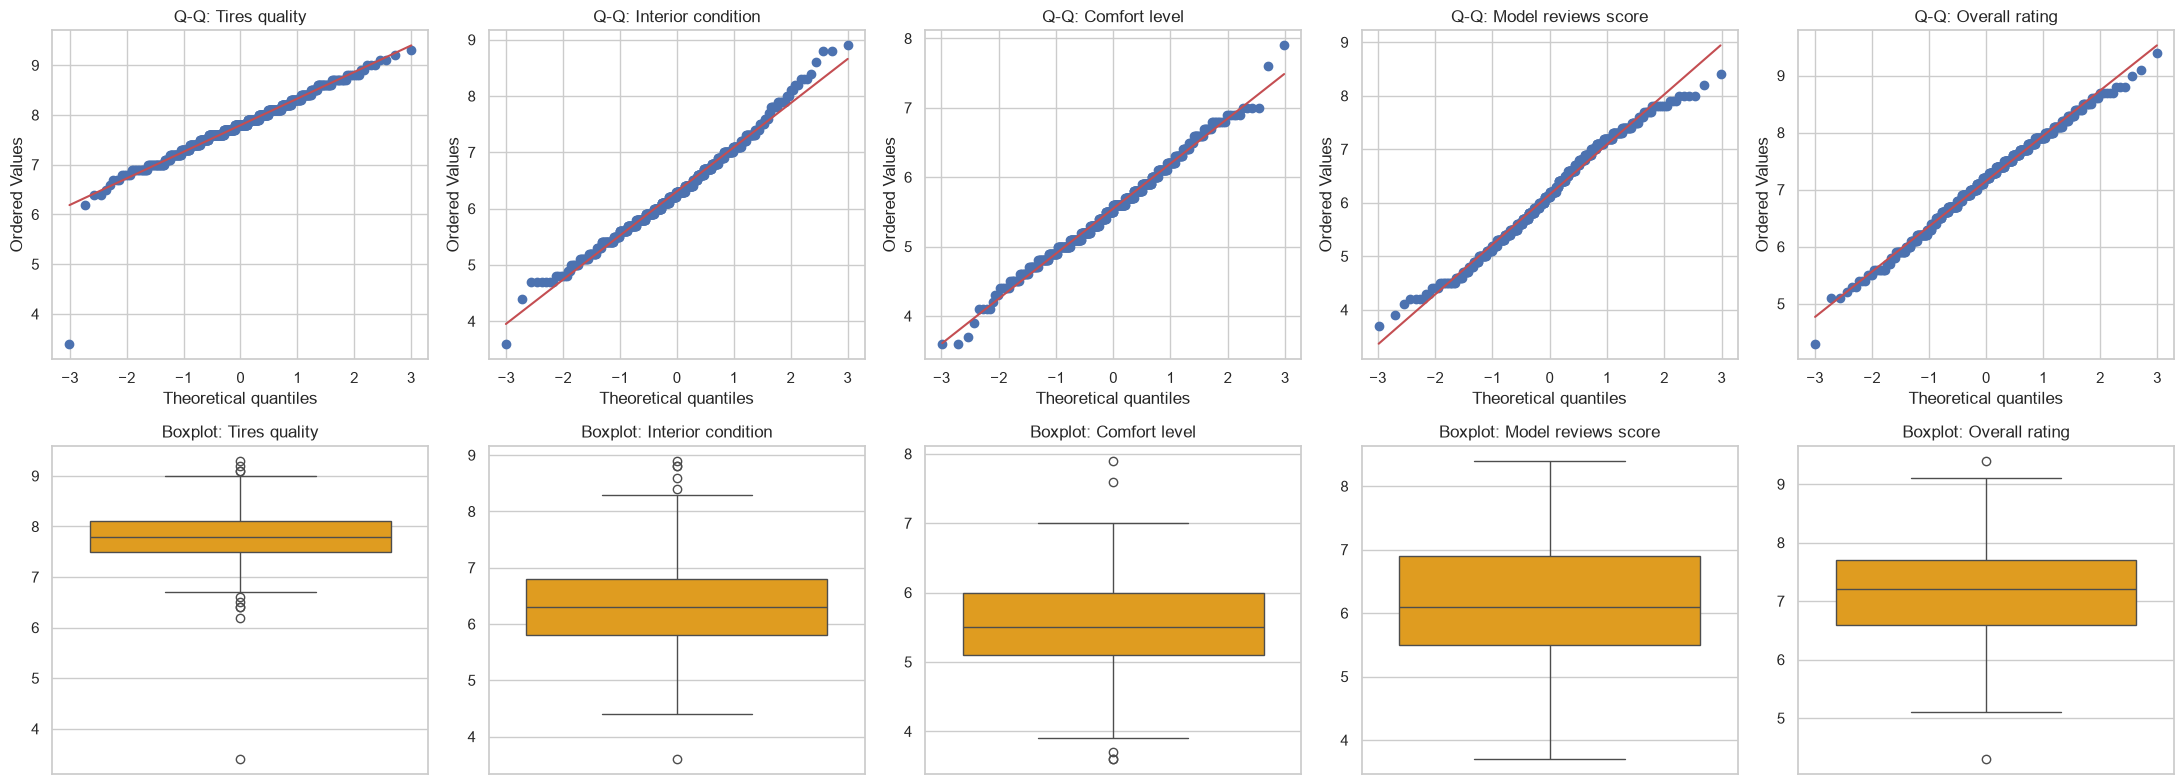

In [17]:
variables_normales = ["Tires quality", "Interior condition", "Comfort level", "Model reviews score", "Overall rating"]

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for i, var in enumerate(variables_normales):
    stats.probplot(train_eda[var].dropna(), dist="norm", plot=axes[0, i])
    axes[0, i].set_title(f"Q-Q: {var}")
    sns.boxplot(y=train_eda[var].dropna(), ax=axes[1, i], color="orange")
    axes[1, i].set_title(f"Boxplot: {var}")
    axes[1, i].set_ylabel("")
plt.tight_layout()
plt.show()

In [ ]:
n_antes = len(train_eda)
for col in variables_normales:
    media, std = train_eda[col].mean(), train_eda[col].std()
    dentro = train_eda[col].between(media - 3*std, media + 3*std)
    train_eda = train_eda[train_eda[col].isna() | dentro]   # los NaN se conservan (los imputaré luego)
X_train = X_train.loc[train_eda.index]
Y_train = Y_train.loc[train_eda.index]
print(f"Filas eliminadas como outliers: {n_antes - len(train_eda)}  -->  train final: {len(X_train)} coches")

Filas eliminadas como outliers: 6  ->  train final: 519 coches


Los Q-Q plots confirman que las cinco valoraciones siguen bastante bien la diagonal (normalidad razonable), salvo algunos puntos aislados en las colas, como un `Tires quality` de 3.5 aproximadamente o un `Interior condition` de 3.6. La regla de $3\sigma$ elimina solo 6 coches , así que la limpieza es conservadora y no perdemos ninguna información que sea relevante.

## Codificación, estandarización e imputación con KNN

El orden que seguiré:

1. Codificar las categóricas con la función `codificar` que he programado antes, la función `align` me garantiza que train y test tengan exactamente las mismas columnas.
2. Estandarizar las continuas con `StandardScaler` antes de imputar, `KNNImputer` busca vecinos por distancia euclídea, y sin escalar algunas variables dominarían a todas las demás variables. `StandardScaler` ignora los NaN al calcular media y desviación, así que se puede aplicar antes de imputar.
3. Imputar con `KNNImputer`: cada NaN se sustituye por la media de los $k$ coches más parecidos, lo que es más realista que la media global. El número de vecinos $k$ es un hiperparámetro, así que no lo fijo a mano: lo elijo por validación cruzada con el criterio fijado (MAE en euros), usando como referencia el modelo más sencillo, la regresión lineal sobre `log(Price)` (la escala que la exploración ha mostrado adecuada). Para que la elección sea honesta, el escalado y la imputación van dentro de un `Pipeline`, de modo que en cada fold se ajustan solo con los datos de entrenamiento de ese fold.
4. `Insurance cost` es binaria, así que redondeamos su valor imputado a 0 o 1.

Todo (escalado e imputación) se ajusta con train y se aplica después al test con `transform`, nunca se preprocesa el test por separado. La variable objetivo no participa en la imputación ya que sería fuga de información (para un coche nuevo no conoceríamos su precio).

In [19]:
X_train = codificar(X_train)
X_test = codificar(X_test)
X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0.0)

# Elección de k (vecinos del KNNImputer) por validación cruzada
pipe_k = Pipeline([
    ("escalado", ColumnTransformer([("cont", StandardScaler(), cont)], remainder="passthrough")),
    ("imputacion", KNNImputer()),
    ("modelo", TransformedTargetRegressor(regressor=LinearRegression(), func=np.log, inverse_func=np.exp)),
])
busqueda_k = GridSearchCV(pipe_k, {"imputacion__n_neighbors": [1, 2, 3, 5, 7, 10, 15, 20, 30, 50]}, cv=cv, scoring=CRITERIO, n_jobs=-1).fit(X_train, Y_train)
k = busqueda_k.best_params_["imputacion__n_neighbors"]
tabla_k = pd.DataFrame({"MAE CV (€)": -busqueda_k.cv_results_["mean_test_score"], "Desv. CV (€)": busqueda_k.cv_results_["std_test_score"]},
                       index=pd.Index(busqueda_k.cv_results_["param_imputacion__n_neighbors"], name="k"))
display(tabla_k.round(1).T)
print(f"k elegido por validación cruzada: {k}\n")

# Preprocesado definitivo: se ajusta con train y se aplica al test
scaler = StandardScaler().set_output(transform="pandas")
X_train[cont] = scaler.fit_transform(X_train[cont])
X_test[cont] = scaler.transform(X_test[cont])

imputer = KNNImputer(n_neighbors=k).set_output(transform="pandas")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

X_train["Insurance cost"] = X_train["Insurance cost"].round()
X_test["Insurance cost"] = X_test["Insurance cost"].round()

print(f"NaN restantes -> train: {X_train.isna().sum().sum()}, test: {X_test.isna().sum().sum()}")
print(f"Columnas ({X_train.shape[1]}): {list(X_train.columns)}")

k,1,2,3,5,7,10,15,20,30,50
MAE CV (€),1000.5,920.4,931.2,974.5,1030.2,1034.0,1028.4,1045.9,1100.2,1168.7
Desv. CV (€),273.0,186.7,187.1,255.1,277.6,245.8,248.2,250.3,258.7,288.9


k elegido por validación cruzada: 2

NaN restantes -> train: 0, test: 0
Columnas (28): ['Engine size', 'Year of manufacture', 'Mileage', 'Tires quality', 'Interior condition', 'Comfort level', 'Sound system quality', 'Model reviews score', 'Overall rating', 'Independent rating', 'Insurance cost', 'Maintenance cost', 'Model_911', 'Model_Cayenne', 'Model_Fiesta', 'Model_Focus', 'Model_Golf', 'Model_M5', 'Model_Mondeo', 'Model_Passat', 'Model_Polo', 'Model_Prius', 'Model_RAV4', 'Model_X3', 'Model_Yaris', 'Model_Z4', 'Fuel type_Hybrid', 'Fuel type_Petrol']


## PCA

El PCA busca las direcciones de máxima varianza, así que depende de la escala de cada variable. Por eso estandarizo todas las columnas (también las dummies y `Insurance cost`) antes de aplicarlo: así todas las variables pesan lo mismo de partida y el resultado no depende de las unidades.

Varianza explicada PC0: 17.68%, PC1: 10.32% (juntas 28.00%)
Componentes necesarias para el 90% de la varianza: 16 de 28


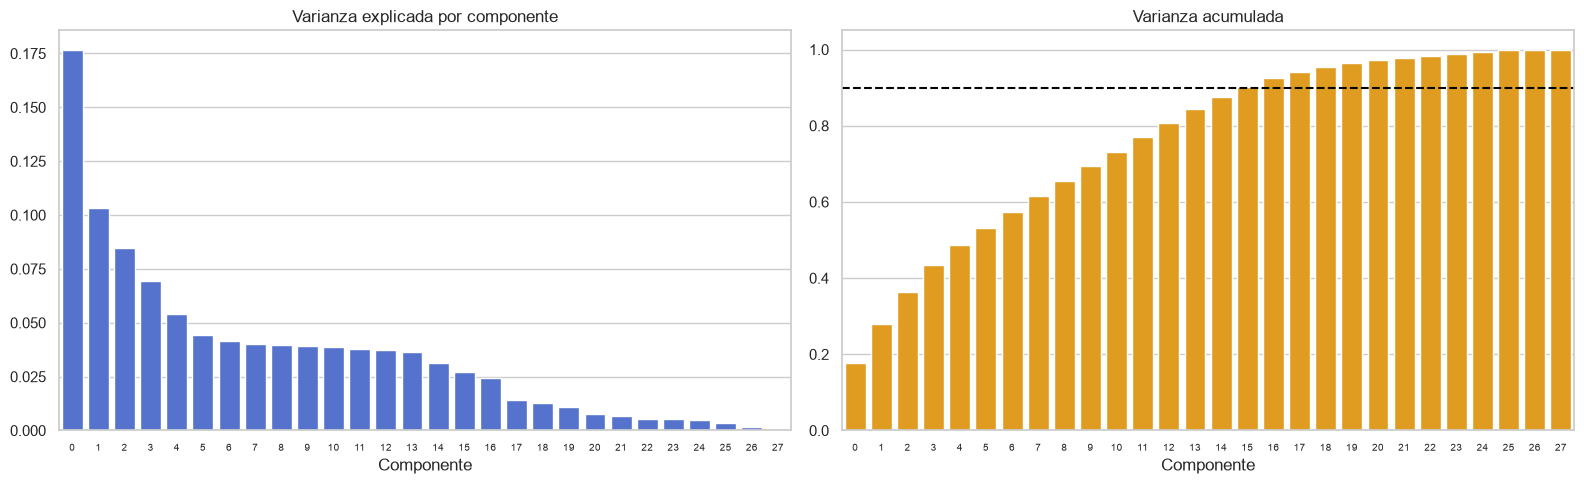

In [20]:
X_pca = StandardScaler().set_output(transform="pandas").fit_transform(X_train)
pca = PCA().set_output(transform="pandas")
componentes = pca.fit_transform(X_pca)
varianza = pca.explained_variance_ratio_
varianza_acumulada = varianza.cumsum()
n90 = np.argmax(varianza_acumulada >= 0.9) + 1
print(f"Varianza explicada PC0: {varianza[0]:.2%}, PC1: {varianza[1]:.2%} (juntas {varianza_acumulada[1]:.2%})")
print(f"Componentes necesarias para el 90% de la varianza: {n90} de {pca.n_components_}")

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(x=np.arange(pca.n_components_), y=varianza, ax=ax[0], color="royalblue")
ax[0].set_title("Varianza explicada por componente")
sns.barplot(x=np.arange(pca.n_components_), y=varianza_acumulada, ax=ax[1], color="orange")
ax[1].axhline(0.9, linestyle="--", color="black")
ax[1].set_title("Varianza acumulada")
for a in ax:
    a.set_xlabel("Componente")
    a.tick_params(axis="x", labelsize=7)
plt.tight_layout()
plt.show()

Con todas las variables estandarizadas, las dos primeras componentes explican solo el 28.0% de la varianza (PC0 17.7%, PC1 10.3%) y hacen falta 16 de las 28 componentes para llegar al 90%. Es lo esperable: al estandarizar, cada dummy de modelo pesa lo mismo que una variable continua, y las dummies son casi independientes entre sí, así que la varianza se reparte entre muchas direcciones. No hay unas pocas direcciones que resuman casi todo.

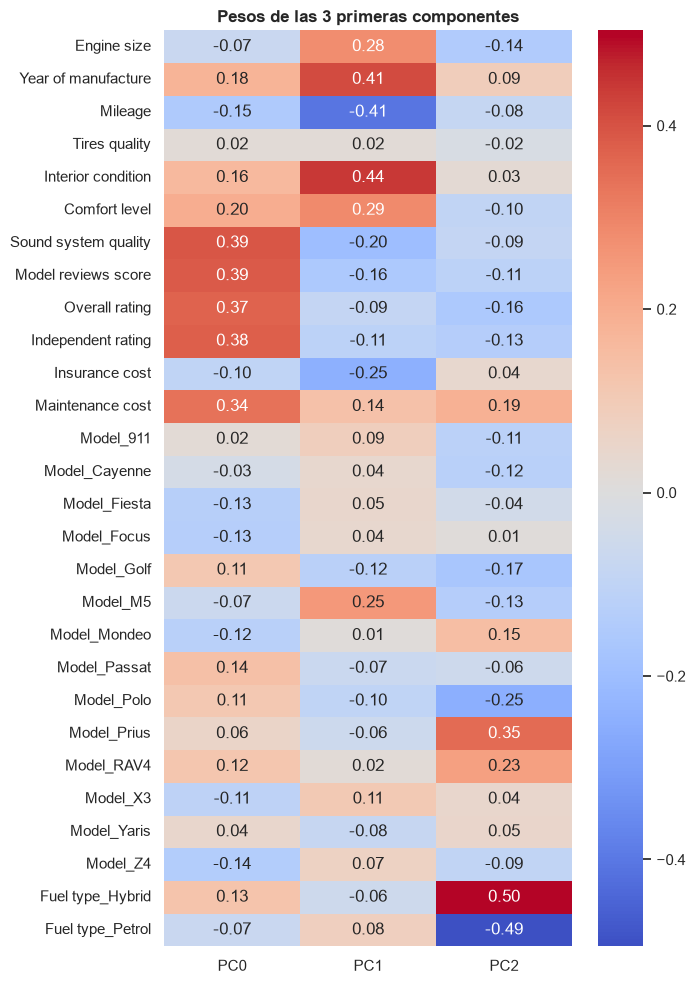

In [21]:
cargas = pd.DataFrame(pca.components_[:3].T, index=X_train.columns, columns=["PC0", "PC1", "PC2"])
plt.figure(figsize=(7, 10))
sns.heatmap(cargas, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Pesos de las 3 primeras componentes", fontweight="bold")
plt.tight_layout()
plt.show()

Interpretación de las componentes:
- PC0: "valoraciones del coche": pesos positivos y parecidos en `Sound system quality`, `Model reviews score`, `Independent rating` y `Overall rating` (~0.38) y en `Maintenance cost` (0.34). Es el bloque de variables correlacionadas que vimos en el mapa de calor.
- PC1: "antigüedad, desgaste y gama": `Interior condition` (+0.44) y `Year of manufacture` (+0.41) frente a `Mileage` (-0.41), y además `Engine size` (+0.28), `Model_M5` (+0.25) y `Comfort level` (+0.29). Un PC1 alto corresponde a un coche nuevo, con pocos kilómetros, interior cuidado y motor grande.
- PC2: "combustible": dominada por `Fuel type_Hybrid` (+0.50) frente a `Fuel type_Petrol` (-0.49), junto a los modelos híbridos típicos (`Prius` +0.35, `RAV4` +0.23).

Al estandarizar, las dummies ya no quedan ocultas por su poca varianza: aparecen en las componentes (M5 en PC1, Prius y RAV4 en PC2).

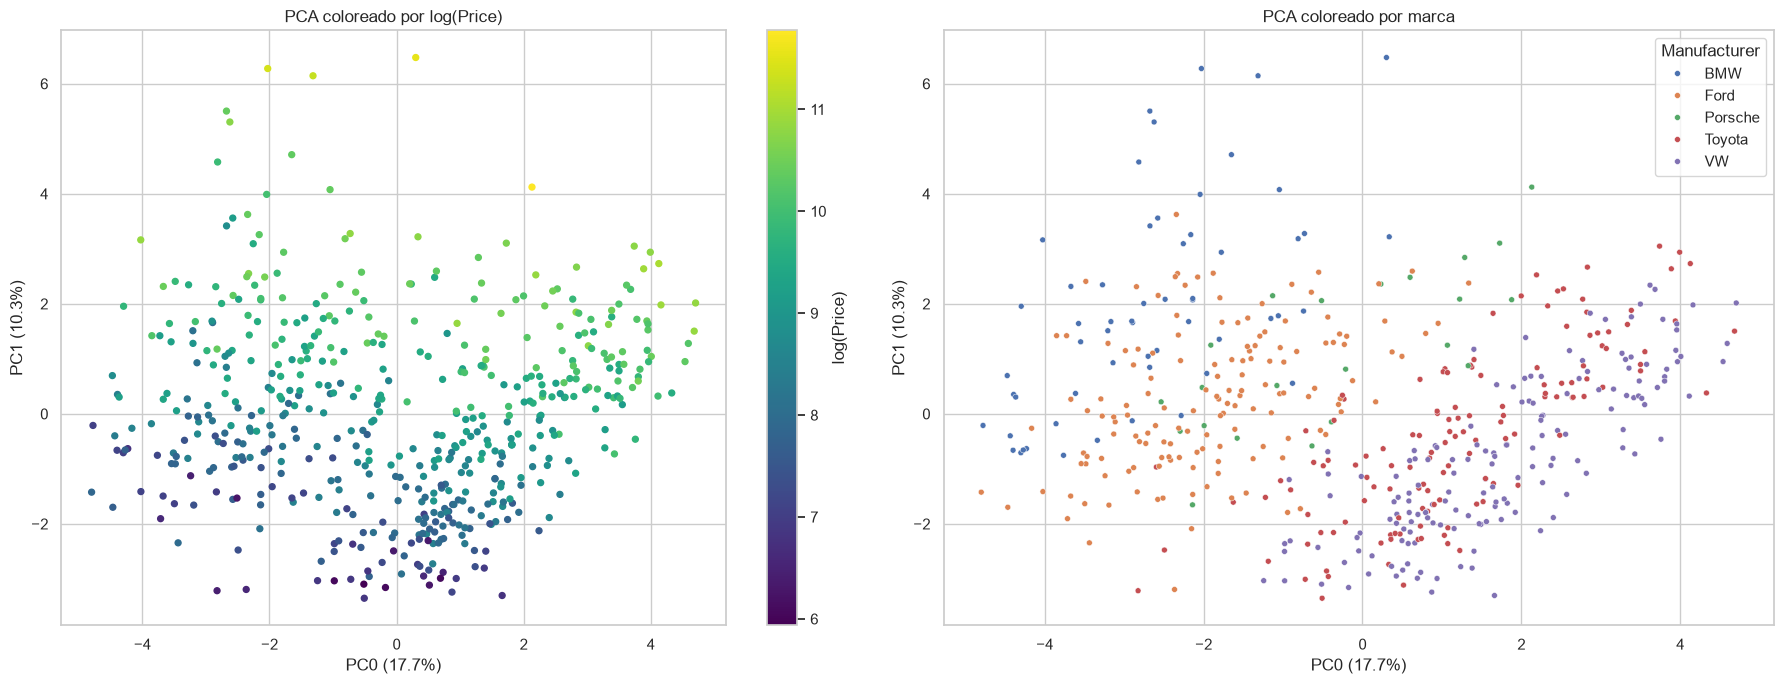

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sc = axes[0].scatter(componentes["pca0"], componentes["pca1"], c=np.log(Y_train), cmap="viridis", s=18)
plt.colorbar(sc, ax=axes[0], label="log(Price)")
axes[0].set_title("PCA coloreado por log(Price)")
marcas = df.loc[X_train.index, "Manufacturer"]   # solo para colorear el gráfico (no entra en el modelo)
sns.scatterplot(x=componentes["pca0"], y=componentes["pca1"], hue=marcas, ax=axes[1], s=18)
axes[1].set_title("PCA coloreado por marca")
for a in axes:
    a.set_xlabel(f"PC0 ({varianza[0]:.1%})")
    a.set_ylabel(f"PC1 ({varianza[1]:.1%})")
plt.tight_layout()
plt.show()

Precio sobre las dos primeras componentes:
- El precio varía sobre todo a lo largo de PC1: los coches caros (amarillo) tienen PC1 alto (nuevos, pocos km, motor grande) y los baratos (morado) PC1 bajo. La correlación entre PC1 y `log(Price)` es de 0.83, lo que confirma que antigüedad y kilometraje son lo que más determina el precio.
- A lo largo de PC0 (valoraciones) el color cambia mucho menos (correlación 0.34 con `log(Price)`), las valoraciones explican poco el precio.
- Coloreando por marca (solo para visualizar) se ve que PC0 separa las marcas: BMW y Ford a la izquierda (valoraciones bajas) y Toyota y VW a la derecha. BMW y Porsche quedan además más arriba en PC1. Las valoraciones dependen más de la marca que del valor del coche.
- No aparecen grupos separados, el precio cambia de forma continua y casi lineal en `log(Price)`, lo que sugiere que un modelo lineal sobre el logaritmo del precio funcionará bien.

# Apartado b) Regresión lineal

## Transformación de las variables

Las variables explicativas ya están transformadas de forma consistente en train y test. Falta decidir qué hacer con la variable objetivo. Empezaré ajustando la regresión lineal sobre el precio original como modelo base, para ver si el resultado es razonable.

Defino las funciones que usaré con todos los modelos, siempre con el criterio fijado en a):
- `en_log`: entrena el modelo sobre `log(Price)` y deshace la transformación con `exp` al predecir, así el error está siempre en euros y es comparable.
- `comparar`: calcula la distribución del MAE en los 10 folds de validación cruzada (media, desviación, mínimo y máximo), que es la estimación del error de generalización, y el MAE en test, que solo uso para comprobar que cae dentro de esa distribución (`z test` cercano a 0, en todo caso con $|z| < 2$). Lo muestra en un boxplot: la caja es la distribución de CV y el rombo rojo el test.

Los residuos los calculo con predicciones de validación cruzada (`cross_val_predict`): cada coche de train se predice con un modelo que no lo ha visto, en lugar de con el modelo ajustado con él.

Predicciones negativas en test: 42 de 225


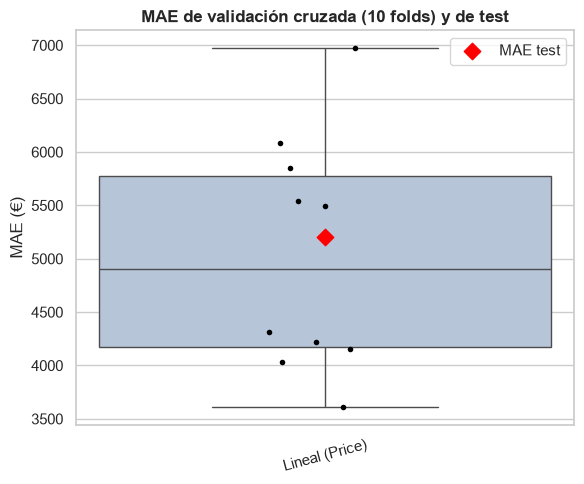

,MAE CV,Desv. CV,Min CV,Max CV,MAE test,z test
Lineal (Price),5027.8,1046.5,3613.1,6970.7,5207.4,0.2


In [23]:
def en_log(modelo):
    """Ajusta el modelo sobre log(Price) y deshace la transformación al predecir, así predice en euros."""
    return TransformedTargetRegressor(regressor=modelo, func=np.log, inverse_func=np.exp)

def errores_cv(modelo, Xtr):
    """MAE (€) en cada fold de validación cruzada. Si es una búsqueda de hiperparámetros, los del valor elegido."""
    if isinstance(modelo, GridSearchCV):
        return np.array([-modelo.cv_results_[f"split{i}_test_score"][modelo.best_index_] for i in range(cv.get_n_splits())])
    return -cross_val_score(modelo, Xtr, Y_train, cv=cv, scoring=CRITERIO)

def comparar(modelos, titulo):
    """Para cada modelo (ya ajustado con train): distribución del MAE de CV y MAE en test para detectar sobreajuste."""
    folds, filas = {}, {}
    for nombre, (modelo, Xtr, Xte) in modelos.items():
        e = errores_cv(modelo, Xtr)
        test = mean_absolute_error(Y_test, modelo.predict(Xte))
        folds[nombre] = e
        filas[nombre] = {"MAE CV": e.mean(), "Desv. CV": e.std(), "Min CV": e.min(), "Max CV": e.max(),
                         "MAE test": test, "z test": (test - e.mean()) / e.std()}
    folds = pd.DataFrame(folds)
    fig, ax = plt.subplots(figsize=(max(6, 2.2 * len(modelos)), 5))
    sns.boxplot(data=folds, ax=ax, color="lightsteelblue")
    sns.stripplot(data=folds, ax=ax, color="black", size=4)
    ax.scatter(range(len(modelos)), [filas[n]["MAE test"] for n in modelos], color="red", marker="D", s=70, zorder=5, label="MAE test")
    ax.set_ylabel("MAE (€)")
    ax.set_title(titulo, fontweight="bold")
    ax.tick_params(axis="x", rotation=15)
    ax.legend()
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(filas).T

lr_raw = LinearRegression().fit(X_train, Y_train)
print(f"Predicciones negativas en test: {(lr_raw.predict(X_test) < 0).sum()} de {len(X_test)}")
comparar({"Lineal (Price)": (lr_raw, X_train, X_test)}, "MAE de validación cruzada (10 folds) y de test").round(1)

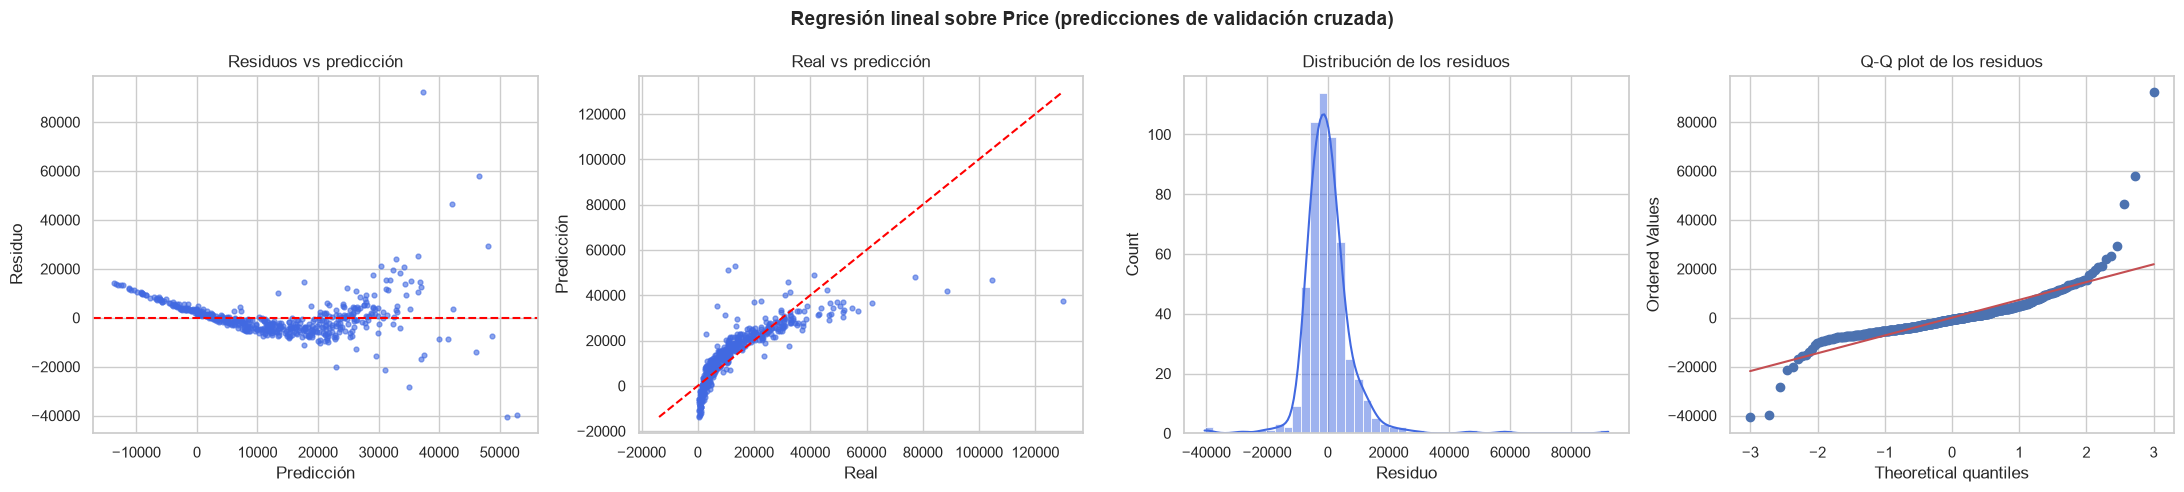

In [24]:
def graficar_residuos(y_real, y_pred, titulo, color="royalblue"):
    residuos = y_real - y_pred
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    axes[0].scatter(y_pred, residuos, s=12, alpha=0.6, color=color)
    axes[0].axhline(0, color="red", linestyle="--")
    axes[0].set_xlabel("Predicción")
    axes[0].set_ylabel("Residuo")
    axes[0].set_title("Residuos vs predicción")
    axes[1].scatter(y_real, y_pred, s=12, alpha=0.6, color=color)
    lim = [min(y_real.min(), y_pred.min()), max(y_real.max(), y_pred.max())]
    axes[1].plot(lim, lim, color="red", linestyle="--")
    axes[1].set_xlabel("Real")
    axes[1].set_ylabel("Predicción")
    axes[1].set_title("Real vs predicción")
    sns.histplot(residuos, kde=True, ax=axes[2], color=color)
    axes[2].set_title("Distribución de los residuos")
    axes[2].set_xlabel("Residuo")
    stats.probplot(residuos, dist="norm", plot=axes[3])
    axes[3].set_title("Q-Q plot de los residuos")
    fig.suptitle(titulo, fontweight="bold", fontsize=14)
    plt.tight_layout()
    plt.show()

# Residuos con predicciones de validación cruzada: cada coche se predice con el modelo que NO lo ha visto
pred_cv_raw = cross_val_predict(LinearRegression(), X_train, Y_train, cv=cv)
graficar_residuos(Y_train, pred_cv_raw, "Regresión lineal sobre Price (predicciones de validación cruzada)")

Se observa que el modelo sobre el precio original no es bueno: el MAE de validación cruzada es de unos 5.030 € (desviación de 1.050 € entre folds). El MAE de test (5.207 €) cae dentro de esa distribución ($z = 0.2$), así que no hay sobreajuste, el modelo es simplemente malo. Además, 42 de los 225 coches de test (19%) tienen precio predicho negativo, lo que no tiene sentido.

Los residuos (de validación cruzada) muestran un patrón muy marcado en forma de U (parábola):
- Para predicciones bajas (incluidas las negativas) los residuos son positivos, el modelo infravalora los coches baratos
- En la zona media los residuos son negativos sobrevalora
- Para predicciones altas vuelven a ser positivos y además mucho más dispersos
- En "Real vs predicción" los puntos forman una curva, no una recta
- Los residuos no son normales, el Q-Q plot tiene una cola derecha muy pesada

Esto incumple las hipótesis de la regresión lineal. La relación entre las variables y el precio no es lineal, es exponencial o multiplicativa, como vimos en la exploración anteriormente.

## Transformación logarítmica del precio

El precio es estrictamente positivo, muy asimétrico, y los efectos parecen multiplicativos (un coche pierde un porcentaje de su valor cada año, no una cantidad fija). Todo ello apunta a modelar $\log(\text{Price})$.
Las predicciones serán siempre positivas, la distribución se vuelve más simétrica, y cada peso se interpreta como un efecto porcentual.

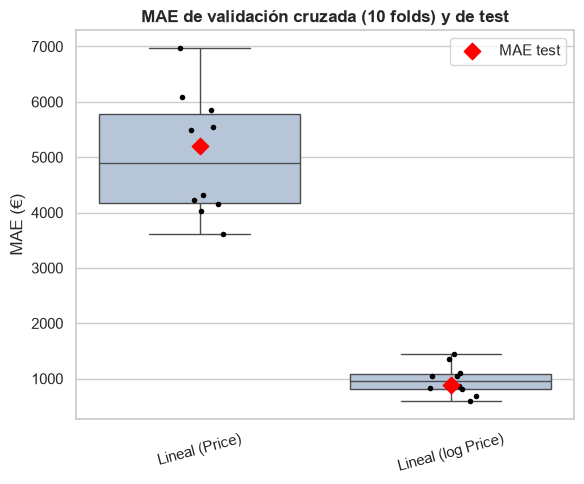

,MAE CV,Desv. CV,Min CV,Max CV,MAE test,z test
Lineal (Price),5027.8,1046.5,3613.1,6970.7,5207.4,0.2
Lineal (log Price),978.3,261.9,594.4,1448.2,885.5,-0.4


In [25]:
Y_train_log = np.log(Y_train)   # solo para el diagnóstico de residuos y el camino de LASSO

lr_log = en_log(LinearRegression()).fit(X_train, Y_train)
metricas_b = comparar({"Lineal (Price)": (lr_raw, X_train, X_test), "Lineal (log Price)": (lr_log, X_train, X_test)},
                      "MAE de validación cruzada (10 folds) y de test")
metricas_b.round(1)

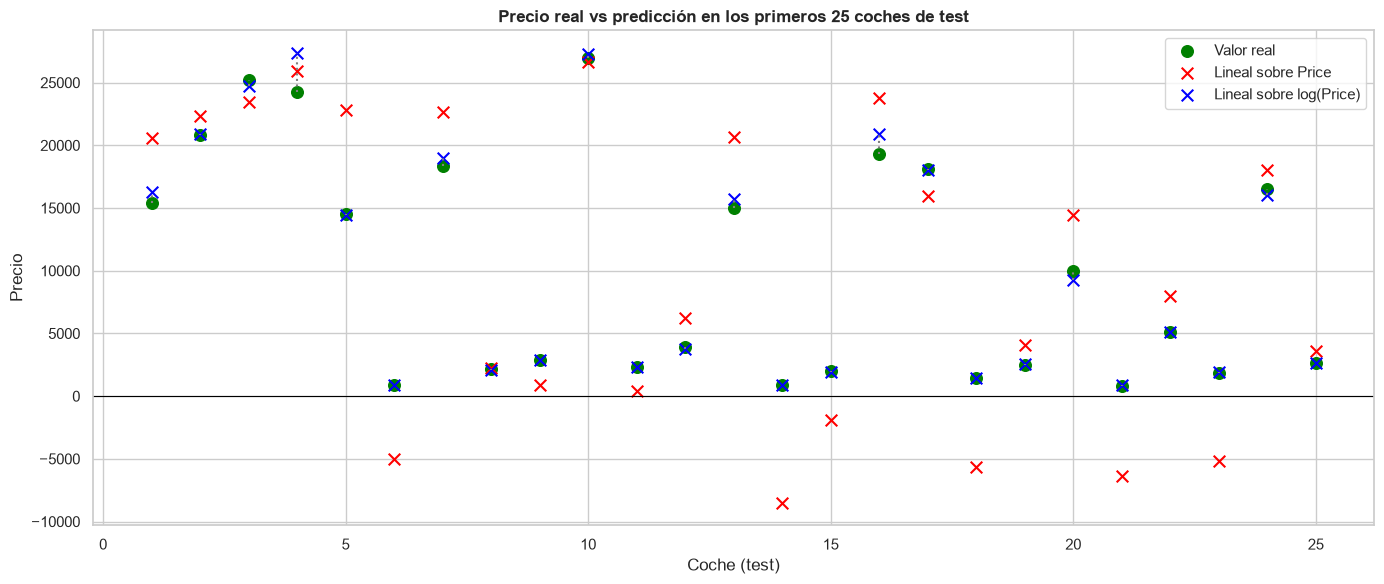

In [26]:
n = 25
pred_raw = lr_raw.predict(X_test)[:n]
pred_log = lr_log.predict(X_test)[:n]
real = Y_test.values[:n]
x = np.arange(1, n + 1)

plt.figure(figsize=(14, 6))
plt.vlines(x, np.minimum(pred_log, real), np.maximum(pred_log, real), color="gray", linestyle=":")
plt.scatter(x, real, s=70, color="green", label="Valor real")
plt.scatter(x, pred_raw, s=70, marker="x", color="red", label="Lineal sobre Price")
plt.scatter(x, pred_log, s=70, marker="x", color="blue", label="Lineal sobre log(Price)")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Coche (test)")
plt.ylabel("Precio")
plt.title(f"Precio real vs predicción en los primeros {n} coches de test", fontweight="bold")
plt.legend()
plt.tight_layout()
plt.show()

La transformación logarítmica mejora el modelo de forma drástica, con el error medido en euros en ambos casos:

| | Lineal (Price) | Lineal (log Price) |
|---|---|---|
| MAE CV (media ± desv.) | 5.028 ± 1.047 € | 978 ± 262 € |
| MAE CV (mín - máx) | 3.613 - 6.971 € | 594 - 1.448 € |
| MAE test | 5.207 € | 886 € |
| $z$ test | 0.2 | -0.4 |

La decisión se toma con el error de validación cruzada: el modelo sobre `log(Price)` tiene un MAE de CV unas 5 veces menor, y sus 10 folds son mejores que el mejor fold del modelo sin transformar. El error esperado con coches nuevos es de unos 980 €.

El MAE de test (886 €) está dentro de la distribución de CV ($z = -0.4$, entre el mínimo y el máximo de los folds), así que el modelo no está sobreajustado y generaliza como esperábamos. En la gráfica, las predicciones del modelo logarítmico (azul) caen casi encima del valor real, mientras que el modelo sin transformar (rojo) da valores negativos y errores de miles de euros. Aun así hay algunos coches con errores grandes (ver los residuos más abajo).

## Pesos del modelo lineal

Analizamos los pesos del modelo con `log(Price)`, que es el bueno. Los pesos del modelo sobre `Price` no los interpreto, ya que ese modelo incumple las hipótesis de la regresión lineal (residuos en forma de U, predicciones negativas), por lo que sus pesos no reflejan el efecto real de cada variable. 

Intercepto: 9.252  -->  precio base 10,422 €


,Peso,Efecto en precio (%)
Model_Polo,-0.684,-49.525
Model_Fiesta,-0.682,-49.460
Model_Yaris,-0.540,-41.736
Mileage,-0.540,-41.727
Model_Golf,-0.470,-37.484
Model_Prius,-0.274,-23.936
Model_Mondeo,-0.268,-23.515
Model_Passat,-0.244,-21.661
Model_Focus,-0.217,-19.502
Model_Z4,-0.161,-14.906


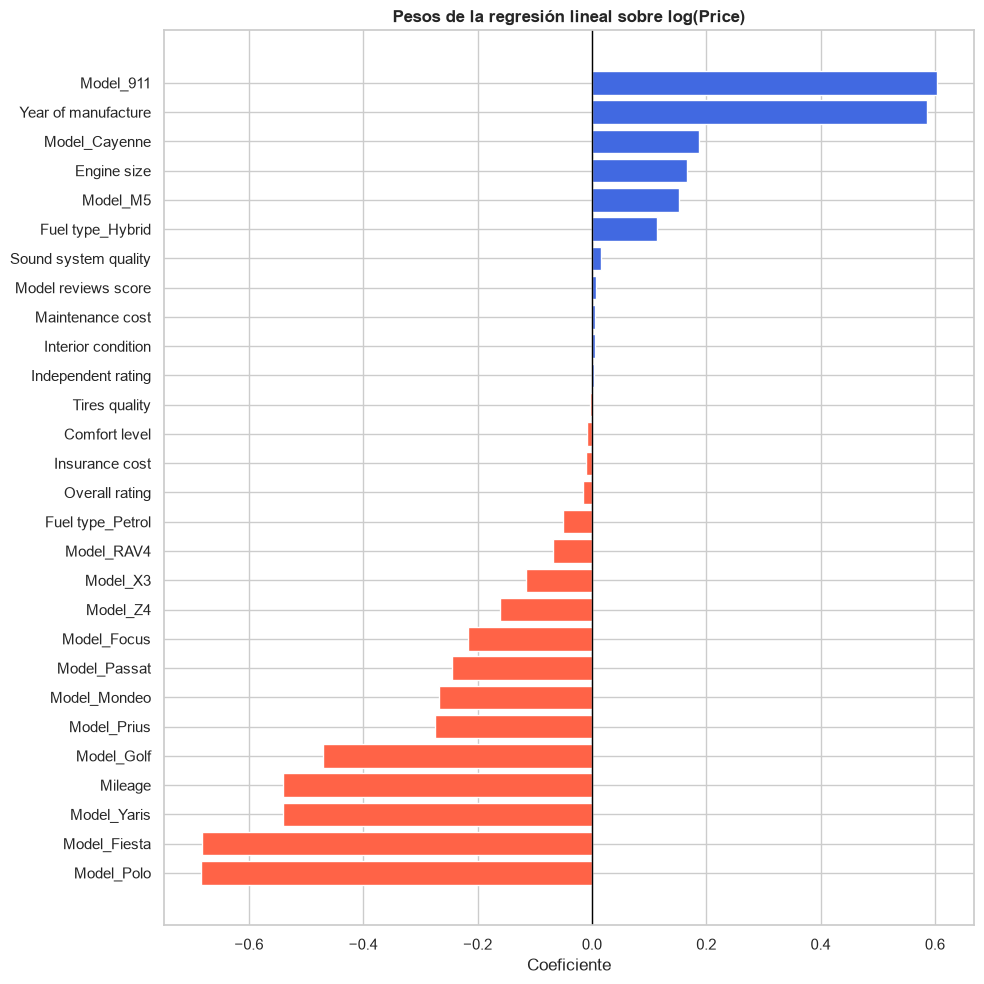

In [27]:
coef_log = lr_log.regressor_.coef_
pesos_lr = pd.DataFrame({"Peso": coef_log, "Efecto en precio (%)": (np.exp(coef_log) - 1)*100},  index=X_train.columns).sort_values("Peso")
print(f"Intercepto: {lr_log.regressor_.intercept_:.3f}  -->  precio base {np.exp(lr_log.regressor_.intercept_):,.0f} €")
display(pesos_lr.round(3))
plt.figure(figsize=(10, 10))
colores = ["tomato" if p < 0 else "royalblue" for p in pesos_lr["Peso"]]
plt.barh(pesos_lr.index, pesos_lr["Peso"], color=colores)
plt.axvline(0, color="black", linewidth=1)
plt.title("Pesos de la regresión lineal sobre log(Price)", fontweight="bold")
plt.xlabel("Coeficiente")
plt.tight_layout()
plt.show()

Interpretación de los pesos:

Variables continuas (efecto de +1 desviación típica):
- `Year of manufacture` (+0.59 -> +80%) es la más importante. Una desviación típica son unos 9.6 años, así que esto equivale a unos +6% de valor por cada año más nuevo. Es decir, el coche se deprecia $\approx$ 6% al año
- `Mileage` (-0.54 -> -42%): cada aproximadamente 64.000 km adicionales el precio baja un 42%. Aun corrigiendo por el año, el kilometraje tiene un efecto propio muy fuerte
- `Engine size` (+0.17 -> +18%): los motores más grandes valen más
- Las valoraciones (`Overall rating`, `Sound system quality`, `Model reviews score`, `Tires quality`, `Comfort level`, `Independent rating`) y `Interior condition` tienen pesos casi nulos (<= 1.7%). Aunque `Interior condition` tenía correlación 0.69 con el precio, una vez que el modelo conoce el año y los kilómetros ya no aporta nada: su correlación era indirecta
- `Insurance cost` y `Maintenance cost` tampoco aportan ($\approx \pm 1$%)

Modelo (respecto al Porsche 718 Cayman, en igualdad de año, km, motor etc...):
- Más caros: `911` (+83%), `Cayenne` (+21%) y `M5` (+16%). Son los deportivos y SUV de gama alta
- Parecidos: `RAV4` (-7%)
- Gama media: `X3` (-11%), `Z4` (-15%), `Focus` (-20%), `Passat` (-22%), `Mondeo` (-24%) y `Prius` (-24%)
- Más baratos: `Golf` (-37%), `Yaris` (-42%), `Fiesta` (-49%) y `Polo` (-50%). Son los utilitarios

El orden de los modelos reproduce la gama de mercado, gama alta (Porsche, BMW) > SUV/berlinas > utilitarios. La marca aparece de forma implícita, todos los Porsche y BMW están arriba y Ford, VW y Toyota abajo. No hace falta `Manufacturer`.
Combustible: híbrido +12% y gasolina -5% respecto a diésel.
Conclusión: el precio se explica sobre todo por antigüedad, kilometraje, modelo y motor. Las valoraciones subjetivas del coche apenas influyen.

## Residuos del modelo con log(Price)

Los residuos se calculan en la escala en la que se ha ajustado el modelo (log), que es donde deben cumplirse las hipótesis de la regresión lineal (media 0, varianza constante, normalidad), y con predicciones de validación cruzada. Además, los representamos frente a las variables más importantes para detectar relaciones no lineales que el modelo no capture.

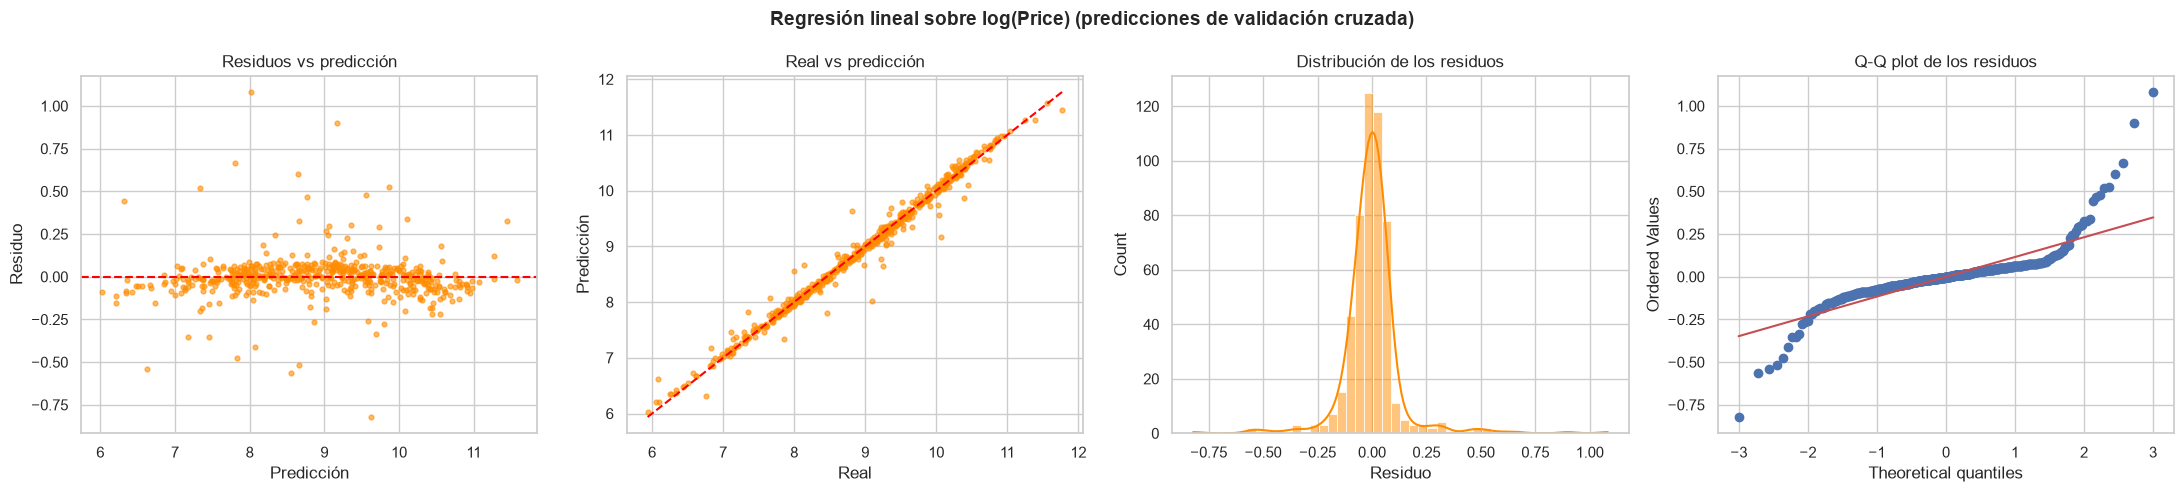

In [28]:
pred_cv_log = np.log(cross_val_predict(en_log(LinearRegression()), X_train, Y_train, cv=cv))
graficar_residuos(Y_train_log, pred_cv_log, "Regresión lineal sobre log(Price) (predicciones de validación cruzada)", color="darkorange")

Residuos del modelo logarítmico:
- Residuos vs predicción: nube centrada en 0 y de anchura constante. El patrón en U ha desaparecido y no hay heterocedasticidad
- Real vs predicción: los puntos están sobre la diagonal
- Distribución: muy concentrada y centrada en 0, pero el Q-Q plot tiene forma de S, con colas pesadas. Algunos coches cuyo precio no se explica con estas variables (ventas atípicas, posibles errores en los datos etc...)

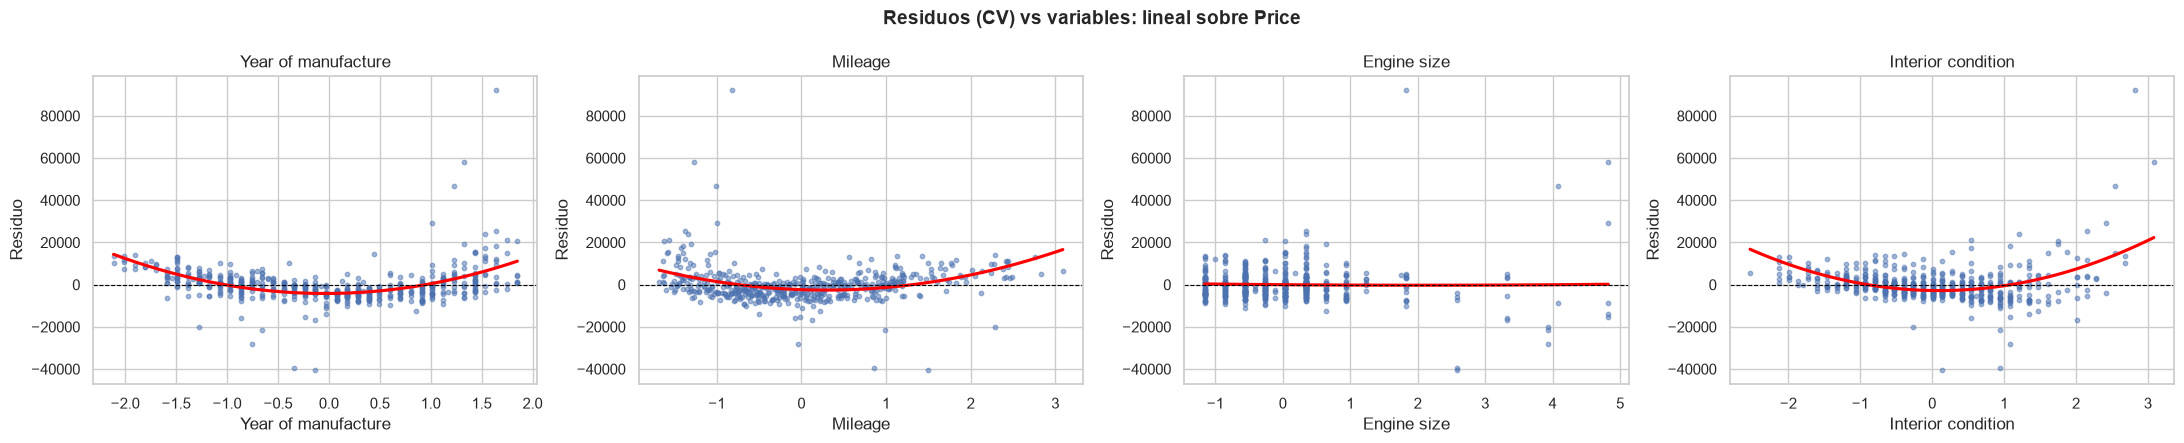

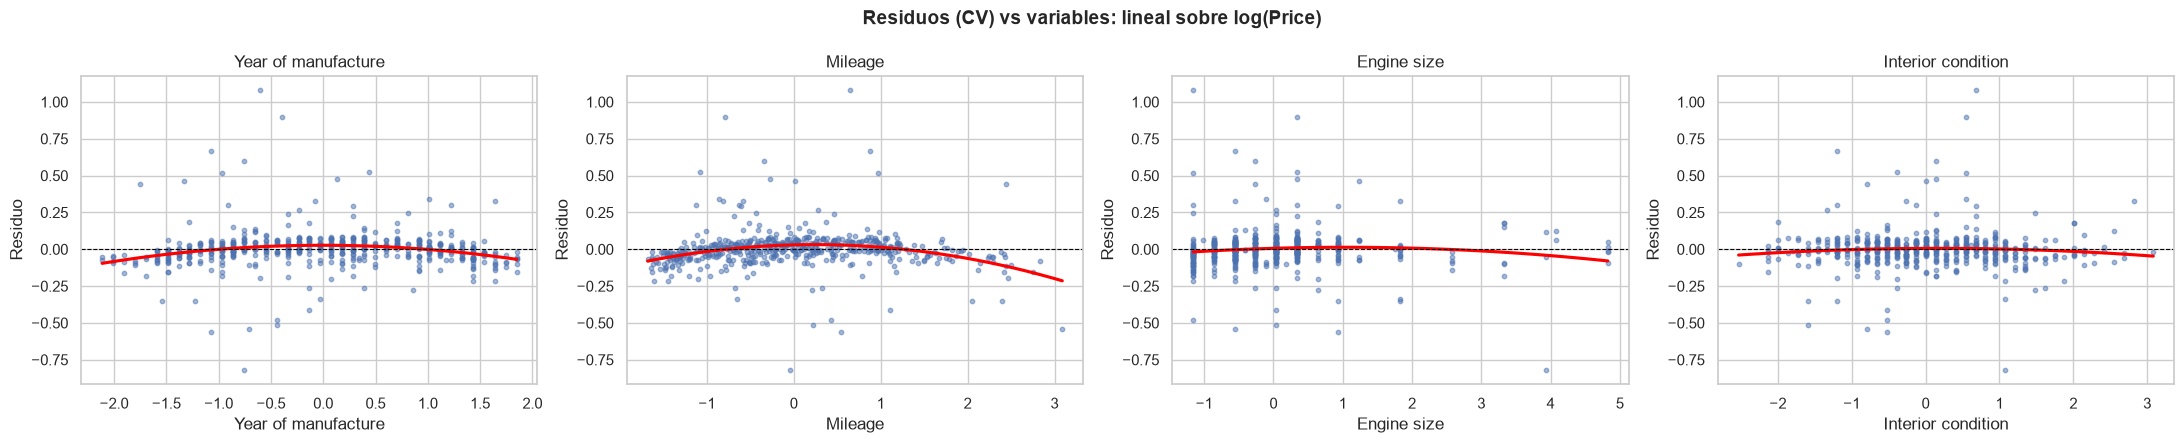

In [29]:
def residuos_vs_variables(residuos, Xdatos, titulo, variables=("Year of manufacture", "Mileage", "Engine size", "Interior condition")):
    fig, axes = plt.subplots(1, len(variables), figsize=(22, 4.5))
    for ax, var in zip(axes, variables):
        sns.regplot(x=Xdatos[var], y=residuos, order=2, ci=None, ax=ax, scatter_kws={"s": 10, "alpha": 0.5}, line_kws={"color": "red"})
        ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
        ax.set_title(var)
        ax.set_ylabel("Residuo")
    fig.suptitle(titulo, fontweight="bold", fontsize=14)
    plt.tight_layout()
    plt.show()

residuos_vs_variables(Y_train - pred_cv_raw, X_train, "Residuos (CV) vs variables: lineal sobre Price")
residuos_vs_variables(Y_train_log - pred_cv_log, X_train, "Residuos (CV) vs variables: lineal sobre log(Price)")



Residuos frente a las variables:
- En el modelo sobre `Price`, la parábola roja muestra una curvatura muy clara frente a `Year of manufacture`, `Mileage` e `Interior condition`. La relación con el precio no es lineal
- En el modelo sobre `log(Price)` las curvas son casi planas. Solo queda una ligera curvatura cóncava en `Mileage`, a kilometrajes muy altos el modelo sobreestima un poco el precio

La transformación logarítmica resuelve casi todo el problema, pero la curvatura en el modelo sin transformar y la ligera curvatura restante son lo que se intenta corregir en el apartado d) con interacciones.

# Apartado c) Ridge y LASSO

El hiperparámetro `alpha` se elige con `GridSearchCV`, con el mismo criterio y las mismas particiones que en el resto del notebook: el MAE en euros en validación cruzada de 10 folds dentro de train (`RidgeCV`/`LassoCV` elegirían por el MSE en escala log, que sería cambiar de criterio). Ajusto sobre `log(Price)` porque en b) la validación cruzada ha mostrado que es la escala adecuada. Compruebo además que el `alpha` elegido no queda en el borde de la rejilla.

Ridge  (log): alpha = 0.0001  <-- borde inferior de la rejilla


Lasso  (log): alpha = 1e-07  <-- borde inferior de la rejilla


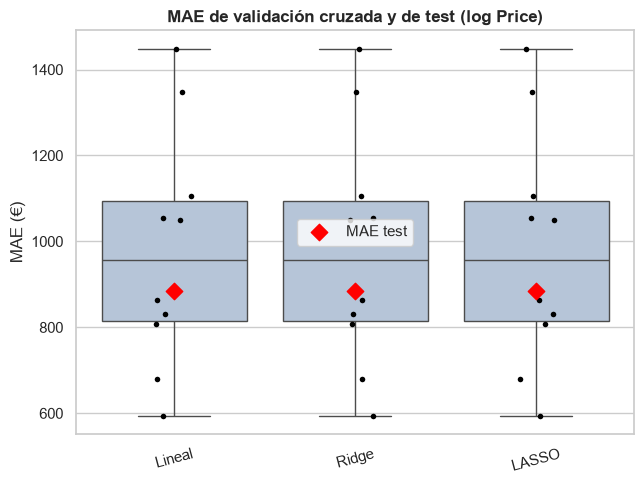

,MAE CV,Desv. CV,Min CV,Max CV,MAE test,z test,Pesos = 0
Lineal,978.3,261.9,594.4,1448.2,885.5,-0.4,0
Ridge,978.3,261.9,594.4,1448.3,885.5,-0.4,0
LASSO,978.3,261.9,594.4,1448.2,885.5,-0.4,0


In [30]:
def coefs(modelo):
    """Pesos del modelo, aunque esté dentro de una búsqueda o de la transformación logarítmica."""
    m = modelo.best_estimator_ if isinstance(modelo, GridSearchCV) else modelo
    return m.regressor_.coef_ if isinstance(m, TransformedTargetRegressor) else m.coef_

def ajustar(modelo, alphas, Xtr, log=True):
    """Elige alpha por validación cruzada (MAE en euros) y reajusta con todo train."""
    est, param = (en_log(modelo), "regressor__alpha") if log else (modelo, "alpha")
    busqueda = GridSearchCV(est, {param: alphas}, cv=cv, scoring=CRITERIO, n_jobs=-1).fit(Xtr, Y_train)
    a = busqueda.best_params_[param]
    aviso = "  <-- borde inferior de la rejilla" if a == alphas[0] else ("  <-- borde superior de la rejilla" if a == alphas[-1] else "")
    print(f"{type(modelo).__name__:6s} ({'log' if log else 'Price'}): alpha = {a:.3g}{aviso}")
    return busqueda

ridge = ajustar(Ridge(), np.logspace(-4, 4, 60), X_train)
lasso = ajustar(Lasso(max_iter=50000), np.logspace(-7, 0, 60), X_train)

metricas_c = comparar({"Lineal": (lr_log, X_train, X_test), "Ridge": (ridge, X_train, X_test), "LASSO": (lasso, X_train, X_test)},
                      "MAE de validación cruzada y de test (log Price)")
metricas_c["Pesos = 0"] = [0, (coefs(ridge) == 0).sum(), (coefs(lasso) == 0).sum()]
metricas_c.round(1)

Con el logaritmo, la validación cruzada elige el `alpha` más pequeño de la rejilla en ambos casos ($10^{-4}$ en Ridge y $10^{-7}$ en LASSO). Que quede en el borde inferior no es un problema de la rejilla: cuando `alpha` tiende a 0, Ridge y LASSO son la regresión lineal, así que bajar más `alpha` solo da el mismo modelo. La regularización óptima es nula. Por eso la distribución del MAE de CV de los tres modelos es idéntica (978 ± 262 €), y su MAE de test (886 €) cae dentro de ella ($z = -0.4$).

Tiene sentido: sin colinealidad y con 28 variables para 519 coches, el modelo lineal no sobreajusta (su error de test está dentro de la distribución de CV), así que no hay varianza que reducir regularizando.

,Lineal,Ridge,LASSO,Lineal - Ridge
Model_Polo,-0.6837,-0.6836,-0.6836,-0.0001
Model_Fiesta,-0.6824,-0.6824,-0.6823,-0.0001
Model_Yaris,-0.5402,-0.5401,-0.5401,-0.0001
Mileage,-0.5400,-0.5400,-0.5400,0.0000
Model_Golf,-0.4697,-0.4697,-0.4696,-0.0001
Model_Prius,-0.2736,-0.2735,-0.2735,-0.0001
Model_Mondeo,-0.2681,-0.2680,-0.2680,-0.0001
Model_Passat,-0.2441,-0.2441,-0.2440,-0.0001
Model_Focus,-0.2169,-0.2169,-0.2169,-0.0001
Model_Z4,-0.1614,-0.1614,-0.1613,-0.0000


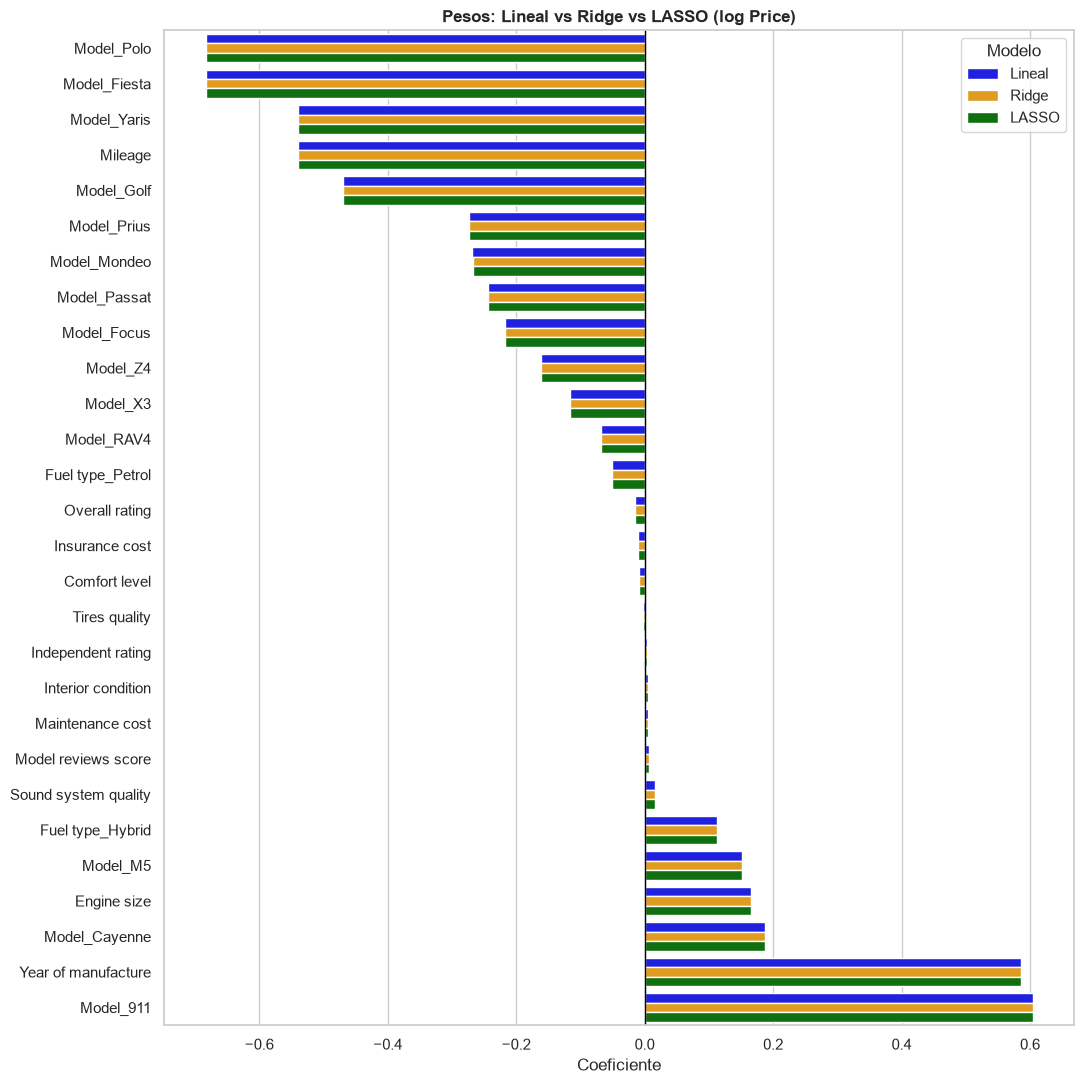

In [31]:
pesos = pd.DataFrame({"Lineal": coefs(lr_log), "Ridge": coefs(ridge), "LASSO": coefs(lasso)}, index=X_train.columns)
pesos["Lineal - Ridge"] = pesos["Lineal"] - pesos["Ridge"]
pesos = pesos.sort_values("Lineal")
display(pesos.round(4))
pesos_largo = (pesos[["Lineal", "Ridge", "LASSO"]].reset_index(names="Variable").melt(id_vars="Variable", var_name="Modelo", value_name="Peso"))

plt.figure(figsize=(11, 11))
sns.barplot(data=pesos_largo, x="Peso", y="Variable", hue="Modelo", order=pesos.index, palette=["blue", "orange", "green"])
plt.axvline(0, color="black", linewidth=1)
plt.title("Pesos: Lineal vs Ridge vs LASSO (log Price)", fontweight="bold")
plt.xlabel("Coeficiente")
plt.ylabel("")
plt.tight_layout()
plt.show()

Lineal vs Ridge: los pesos son prácticamente idénticos. La mayor diferencia es de 0.0001, porque el alpha elegido es casi 0. Esto indica que los pesos del modelo lineal son estables y no están "inflados" por colinealidad, y Ridge no tiene nada que corregir.

### Camino de regularización de LASSO

Para ver qué variables considera prescindibles LASSO represento el camino de regularización (cómo evoluciona cada peso al aumentar `alpha`) y el error de validación cruzada (MAE en euros, el criterio de siempre). Además utilizo la regla de 1 error estándar: el `alpha` más grande cuyo MAE de CV no supera el mínimo más un error estándar. Da un modelo más simple con un rendimiento estadísticamente equivalente.

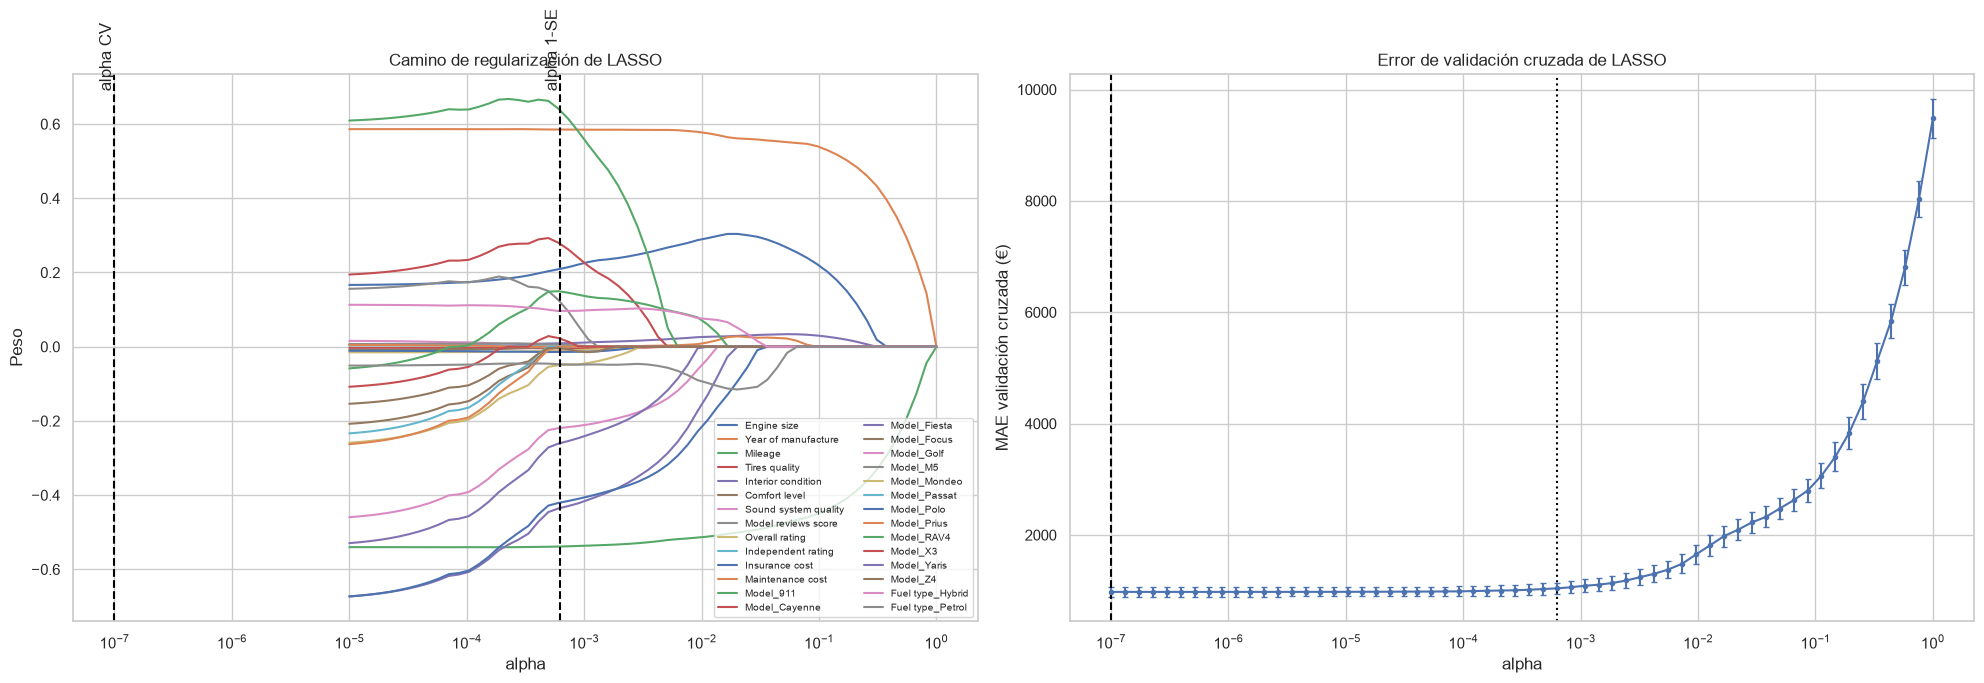

alpha CV: 1e-07   alpha 1-SE: 0.000626
Variables eliminadas con alpha CV (0): []
Variables eliminadas con alpha 1-SE (4): ['Sound system quality', 'Maintenance cost', 'Model_Passat', 'Model_Prius']


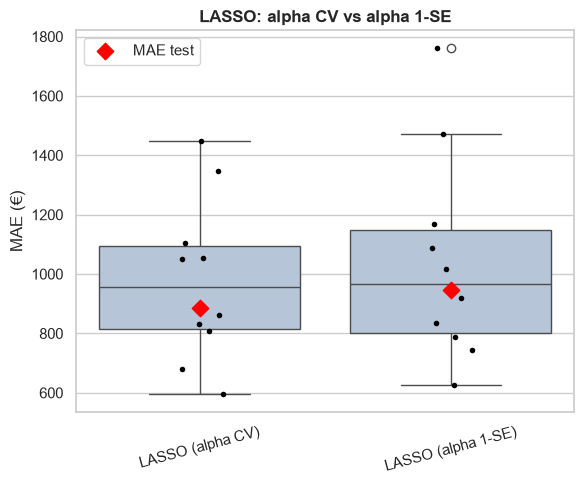

,MAE CV,Desv. CV,Min CV,Max CV,MAE test,z test
LASSO (alpha CV),978.3,261.9,594.4,1448.2,885.5,-0.4
LASSO (alpha 1-SE),1041.8,332.2,627.3,1762.0,947.8,-0.3


In [32]:
res = lasso.cv_results_
alphas_cv = res["param_regressor__alpha"].astype(float)
mae_folds = -np.array([res[f"split{i}_test_score"] for i in range(cv.get_n_splits())])   # (folds, alphas)
mae_medio = mae_folds.mean(axis=0)
mae_se = mae_folds.std(axis=0) / np.sqrt(cv.get_n_splits())
idx_min = np.argmin(mae_medio)
alpha_cv = alphas_cv[idx_min]
alpha_1se = alphas_cv[mae_medio <= mae_medio[idx_min] + mae_se[idx_min]].max()

alphas_camino = np.logspace(-5, 0, 60)
camino = pd.DataFrame([Lasso(alpha=a, max_iter=50000).fit(X_train, Y_train_log).coef_ for a in alphas_camino], index=alphas_camino, columns=X_train.columns)

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
for col in camino.columns:
    axes[0].plot(camino.index, camino[col], label=col)
for a, txt in [(alpha_cv, "alpha CV"), (alpha_1se, "alpha 1-SE")]:
    axes[0].axvline(a, color="black", linestyle="--")
    axes[0].text(a, axes[0].get_ylim()[1]*0.95, txt, rotation=90, ha="right")
axes[0].set_xscale("log")
axes[0].set_xlabel("alpha")
axes[0].set_ylabel("Peso")
axes[0].set_title("Camino de regularización de LASSO")
axes[0].legend(fontsize=7, ncol=2, loc="lower right")
axes[1].errorbar(alphas_cv, mae_medio, yerr=mae_se, fmt="o-", markersize=3, capsize=2)
axes[1].axvline(alpha_cv, color="black", linestyle="--")
axes[1].axvline(alpha_1se, color="black", linestyle=":")
axes[1].set_xscale("log")
axes[1].set_xlabel("alpha")
axes[1].set_ylabel("MAE validación cruzada (€)")
axes[1].set_title("Error de validación cruzada de LASSO")
plt.tight_layout()
plt.show()

lasso_1se = en_log(Lasso(alpha=alpha_1se, max_iter=50000)).fit(X_train, Y_train)
print(f"alpha CV: {alpha_cv:.3g}   alpha 1-SE: {alpha_1se:.3g}")
print(f"Variables eliminadas con alpha CV ({(coefs(lasso) == 0).sum()}): {list(X_train.columns[coefs(lasso) == 0])}")
print(f"Variables eliminadas con alpha 1-SE ({(coefs(lasso_1se) == 0).sum()}): {list(X_train.columns[coefs(lasso_1se) == 0])}")
comparar({"LASSO (alpha CV)": (lasso, X_train, X_test), "LASSO (alpha 1-SE)": (lasso_1se, X_train, X_test)},
         "LASSO: alpha CV vs alpha 1-SE").round(1)

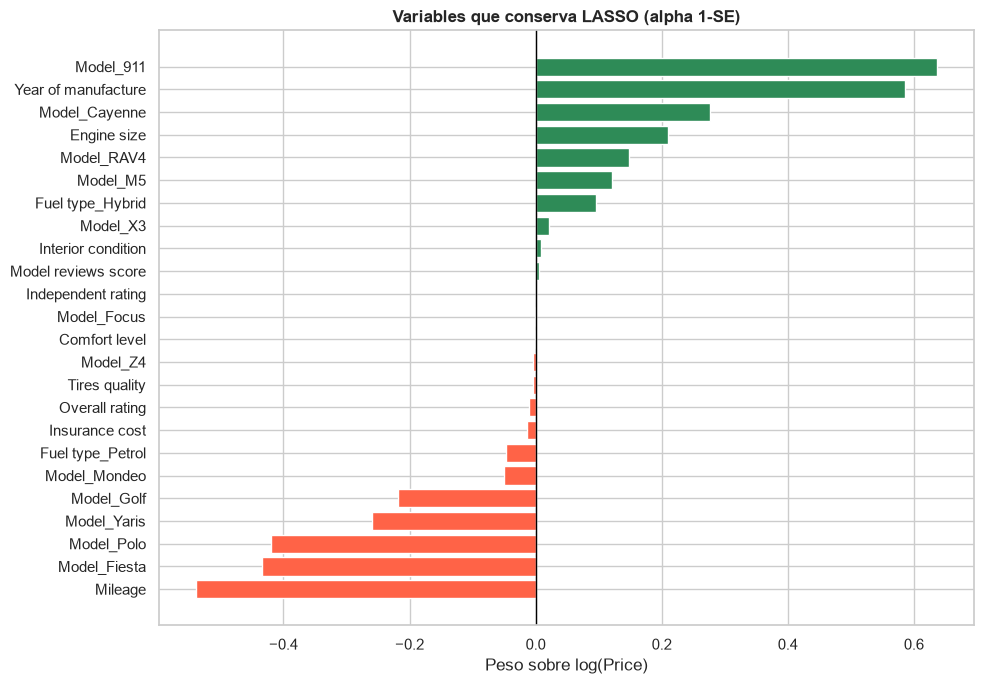

In [33]:
pesos_lasso = pd.Series(coefs(lasso_1se), index=X_train.columns)
pesos_lasso = pesos_lasso[pesos_lasso != 0].sort_values()
plt.figure(figsize=(10, 7))
plt.barh(pesos_lasso.index, pesos_lasso.values, color=["tomato" if p < 0 else "seagreen" for p in pesos_lasso])
plt.axvline(0, color="black", linewidth=1)
plt.title("Variables que conserva LASSO (alpha 1-SE)", fontweight="bold")
plt.xlabel("Peso sobre log(Price)")
plt.tight_layout()
plt.show()

Al aumentar `alpha` los pesos se van anulando. Los primeros en desaparecer son las valoraciones y los costes (sonido, mantenimiento, confort, reseñas etc...) junto con las dummies de los modelos de gama media (`RAV4`, `X3`, `Passat`, `Prius`, `Focus`), que caen a 0 en cuanto alpha crece un poco. Después se van anulando las demás dummies de modelo y el combustible. Las últimas en sobrevivir son `Engine size`, `Interior condition` y, sobre todo, `Year of manufacture` y `Mileage` (hasta alpha $\approx$ 1). Este orden es un ranking de importancia de las variables.

La curva de MAE de CV es casi plana hasta alpha $\approx 10^{-4}$ y después sube rápidamente. Con la regla de 1 error estándar (alpha $= 6.3·10^{-4}$) LASSO elimina 4 variables: `Sound system quality`, `Maintenance cost`, `Model_Passat` y `Model_Prius`, y deja las demás valoraciones, `Model_Focus` y `Model_Z4` con pesos casi nulos. Su MAE de CV es de 1.042 ± 332 €, frente a 978 ± 262 € con el alpha óptimo: la diferencia (64 €) es menor que un error estándar del mejor (83 €), así que su rendimiento es estadísticamente equivalente con un modelo algo más simple. Su MAE de test (948 €) también cae dentro de su distribución de CV ($z = -0.3$).

Las variables desaparecen debido a que:
- `Sound system quality` y `Maintenance cost` (y casi todas las demás valoraciones): ya vimos que no tienen relación con el precio una vez conocidos año y km, y además son redundantes con el resto de valoraciones
- `Passat` y `Prius` (y casi `Focus` y `Z4`): son modelos de gama media, con pesos intermedios en el modelo lineal. LASSO los junta con la categoría de referencia y crea un único grupo de gama media. El efecto que se pierde lo absorbe en parte `Engine size`, que sube de 0.17 a 0.21. LASSO conserva separados sobre todo los extremos, gama alta (`911`, `Cayenne`, `M5`, `RAV4`) y utilitarios o gama baja (`Fiesta`, `Polo`, `Yaris`, `Golf`)

¿Tienen sentido las variables con más y menos peso? Sí, el modelo explica el precio de un coche de forma muy intuitiva:
1. Cuántos años tiene
2. Cuántos kilómetros lleva
3. Qué coche es: la gama del modelo (deportivo/premium, gama media o utilitario) y el tamaño del motor
4. En menor medida, el combustible (los híbridos valen más)

Por el contrario, las valoraciones subjetivas (reseñas, sonido, confort, puntuación general etc...) y los costes de seguro y mantenimiento no influyen en el precio. Es lo que haría un tasador real, él miraría la ficha del coche (modelo, año, km, motor), no las opiniones.

# Apartado d) Interacciones con PolynomialFeatures

En el apartado b) vimos que la regresión lineal sobre el precio original deja un patrón muy claro en los residuos: forma de U (parábola) frente a la predicción y frente al año. Eso indica que la relación entre las variables y el precio no es aditiva, por ejemplo, un año más de antigüedad no resta los mismos euros a un Porsche 911 que a un Ford Fiesta, y el kilometraje penaliza distinto según el año.

`PolynomialFeatures(degree=2)` añade todos los productos de dos variables $x_i x_j$ (interacciones) y los cuadrados $x_i^2$. Detalles que tengo en cuenta:
- Con variables dummy, $x_i^2 = x_i$ (duplicado) y el producto de dos dummies excluyentes (dos modelos distintos) es siempre 0. Elimino  esas columnas constantes o duplicadas porque no aportan nada
- Volvemos a estandarizar tras crear las variables (ajustando el escalado con train y aplicándolo al test), los productos tienen escalas muy distintas y Ridge/LASSO necesitan variables comparables
- Con tantas variables como datos, la regresión sin regularizar sobreajustaría, por eso aplicaremos Ridge y LASSO, con `alpha` elegido por validación cruzada con el mismo criterio (MAE en euros, 10 folds)

Ajustamos los modelos en las dos escalas del objetivo: sobre `Price` (donde estaba el problema de los residuos) y sobre `log(Price)` (nuestro mejor modelo hasta ahora). Todos se comparan con la distribución del MAE de validación cruzada, y el test solo se usa para comprobar el sobreajuste.

In [34]:
poly = PolynomialFeatures(degree=2, include_bias=False).set_output(transform="pandas")
P_train = poly.fit_transform(X_train)
P_test = poly.transform(X_test)
print(f"Variables generadas: {P_train.shape[1]}")

# Quitamos columnas constantes (productos de dummies excluyentes) y duplicadas (cuadrados de dummies)
utiles = P_train.columns[P_train.std() > 0]
P_train = P_train[utiles].T.drop_duplicates().T
P_test = P_test[P_train.columns]
print(f"Variables tras eliminar constantes y duplicadas: {P_train.shape[1]}  (filas de train: {P_train.shape[0]})")

scaler_poly = StandardScaler().set_output(transform="pandas")
P_train = scaler_poly.fit_transform(P_train)
P_test = scaler_poly.transform(P_test)

Variables generadas: 434
Variables tras eliminar constantes y duplicadas: 313  (filas de train: 519)


Ridge  (Price): alpha = 168


Lasso  (Price): alpha = 1.19e+03


Ridge  (Price): alpha = 25.6


Lasso  (Price): alpha = 49.2


Ridge  (log): alpha = 32.4


Lasso  (log): alpha = 0.00702


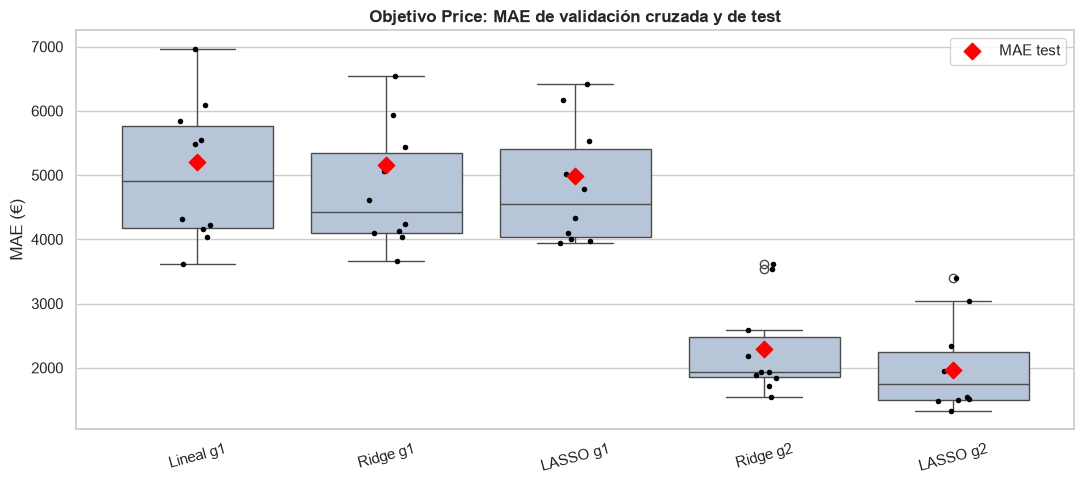

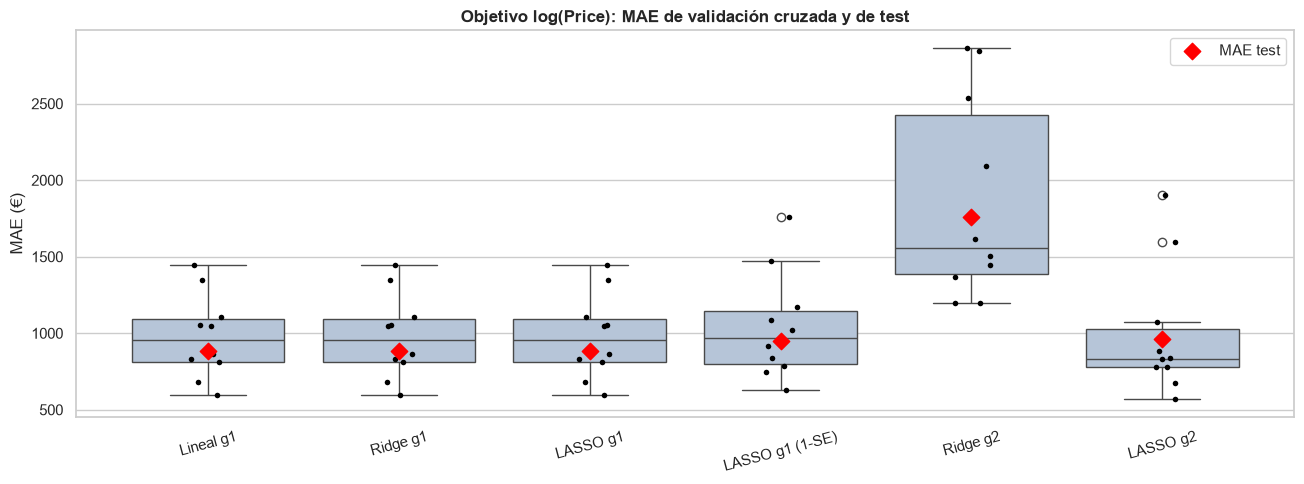

MAE CV  Desv. CV  Min CV  Max CV  MAE test  \
Objetivo   Modelo                                                        
Price      Lineal g1        5027.8    1046.5  3613.1  6970.7    5207.4   
           Ridge g1         4776.3     894.1  3668.7  6546.1    5150.0   
           LASSO g1         4826.9     883.5  3948.2  6414.9    4982.6   
           Ridge g2         2277.0     702.7  1548.1  3619.7    2294.0   
           LASSO g2         2003.8     674.6  1330.9  3394.1    1971.9   
log(Price) Lineal g1         978.3     261.9   594.4  1448.2     885.5   
           Ridge g1          978.3     261.9   594.4  1448.3     885.5   
           LASSO g1          978.3     261.9   594.4  1448.2     885.5   
           LASSO g1 (1-SE)  1041.8     332.2   627.3  1762.0     947.8   
           Ridge g2         1865.5     630.4  1194.4  2863.3    1756.1   
           LASSO g2          992.6     403.9   569.4  1903.7     963.8   

                            z test  Pesos != 0  
Objetivo   Modelo                               
Price      Lineal g1           0.2          28  
           Ridge g1            0.4          28  
           LASSO g1            0.2           4  
           Ridge g2            0.0         313  
           LASSO g2           -0.0         115  
log(Price) Lineal g1          -0.4          28  
           Ridge g1           -0.4          28  
           LASSO g1           -0.4          28  
           LASSO g1 (1-SE)    -0.3          24  
           Ridge g2           -0.2         313  
           LASSO g2           -0.1          52

In [35]:
ridge_raw   = ajustar(Ridge(), np.logspace(-3, 5, 50), X_train, log=False)
lasso_raw   = ajustar(Lasso(max_iter=100000), np.logspace(-2, 4, 40), X_train, log=False)
ridge_p_raw = ajustar(Ridge(), np.logspace(-3, 5, 50), P_train, log=False)
lasso_p_raw = ajustar(Lasso(max_iter=100000), np.logspace(-2, 4, 40), P_train, log=False)
ridge_p_log = ajustar(Ridge(), np.logspace(-4, 5, 50), P_train)
lasso_p_log = ajustar(Lasso(max_iter=100000), np.logspace(-6, 0, 40), P_train)

modelos_price = {
    "Lineal g1": (lr_raw, X_train, X_test), "Ridge g1": (ridge_raw, X_train, X_test), "LASSO g1": (lasso_raw, X_train, X_test),
    "Ridge g2": (ridge_p_raw, P_train, P_test), "LASSO g2": (lasso_p_raw, P_train, P_test),
}
modelos_log = {
    "Lineal g1": (lr_log, X_train, X_test), "Ridge g1": (ridge, X_train, X_test), "LASSO g1": (lasso, X_train, X_test),
    "LASSO g1 (1-SE)": (lasso_1se, X_train, X_test),
    "Ridge g2": (ridge_p_log, P_train, P_test), "LASSO g2": (lasso_p_log, P_train, P_test),
}
m_price = comparar(modelos_price, "Objetivo Price: MAE de validación cruzada y de test")
m_log = comparar(modelos_log, "Objetivo log(Price): MAE de validación cruzada y de test")
metricas_d = pd.concat({"Price": m_price, "log(Price)": m_log}, names=["Objetivo", "Modelo"])
metricas_d["Pesos != 0"] = [(coefs(m) != 0).sum() for m, _, _ in list(modelos_price.values()) + list(modelos_log.values())]
metricas_d.round(1)

In [36]:
# Selección del mejor modelo: SOLO con el error de validación cruzada
ranking = metricas_d.sort_values("MAE CV")
mejor = ranking.index[0]
se_mejor = ranking.loc[mejor, "Desv. CV"] / np.sqrt(cv.get_n_splits())
ranking["Equivalente al mejor (1-SE)"] = ranking["MAE CV"] <= ranking.loc[mejor, "MAE CV"] + se_mejor
print(f"Mejor MAE de CV: {mejor} ({ranking.loc[mejor, 'MAE CV']:.0f} €, error estándar {se_mejor:.0f} €)")
ranking[["MAE CV", "Desv. CV", "MAE test", "z test", "Pesos != 0", "Equivalente al mejor (1-SE)"]].round(1)

Mejor MAE de CV: ('log(Price)', 'Lineal g1') (978 €, error estándar 83 €)


MAE CV  Desv. CV  MAE test  z test  Pesos != 0  \
Objetivo   Modelo                                                            
log(Price) Lineal g1         978.3     261.9     885.5    -0.4          28   
           Ridge g1          978.3     261.9     885.5    -0.4          28   
           LASSO g1          978.3     261.9     885.5    -0.4          28   
           LASSO g2          992.6     403.9     963.8    -0.1          52   
           LASSO g1 (1-SE)  1041.8     332.2     947.8    -0.3          24   
           Ridge g2         1865.5     630.4    1756.1    -0.2         313   
Price      LASSO g2         2003.8     674.6    1971.9    -0.0         115   
           Ridge g2         2277.0     702.7    2294.0     0.0         313   
           Ridge g1         4776.3     894.1    5150.0     0.4          28   
           LASSO g1         4826.9     883.5    4982.6     0.2           4   
           Lineal g1        5027.8    1046.5    5207.4     0.2          28   

                            Equivalente al mejor (1-SE)  
Objetivo   Modelo                                        
log(Price) Lineal g1                               True  
           Ridge g1                                True  
           LASSO g1                                True  
           LASSO g2                                True  
           LASSO g1 (1-SE)                         True  
           Ridge g2                               False  
Price      LASSO g2                               False  
           Ridge g2                               False  
           Ridge g1                               False  
           LASSO g1                               False  
           Lineal g1                              False

Sobre `Price`: sí, ha mejorado bastante. El MAE de validación cruzada pasa de 4.780-5.030 € (grado 1) a 2.004 ± 675 € con LASSO de grado 2 (2.277 ± 703 € con Ridge). Las distribuciones de CV ni se solapan: el peor fold de LASSO grado 2 (3.394 €) es mejor que el mejor fold del lineal de grado 1 (3.613 €). Las interacciones permiten modelar los efectos no aditivos que el modelo lineal no podía capturar. El MAE de test de todos los modelos está dentro de su distribución de CV ($|z| \le 0.4$), así que ni siquiera Ridge con 313 variables está sobreajustado: la regularización elegida por CV lo controla. Aun así LASSO grado 2 sigue dando 9 precios negativos en test para coches muy baratos.

Sobre `log(Price)`: no mejora.
- LASSO grado 2 obtiene un MAE de CV de 993 ± 404 €, prácticamente igual que el lineal de grado 1 (978 ± 262 €): la diferencia (15 €) es mucho menor que un error estándar (83 €). Además su error es más variable entre folds (desviación de 404 € frente a 262 €, peor fold 1.904 € frente a 1.448 €), es decir, es menos estable.
- Ridge grado 2 empeora claramente (MAE de CV de 1.866 ± 630 €, casi el doble). Con 313 variables para 519 coches, Ridge no puede anular las interacciones inútiles, solo encogerlas, y para controlar la varianza necesita un `alpha` alto (32) que sesga también los efectos importantes. LASSO sí las elimina (se queda con 52 variables) y aguanta mucho mejor.
- El MAE de test de todos ellos cae dentro de su distribución de CV ($|z| \le 0.4$), así que no hay sobreajuste que corregir.

Elección del modelo (solo con la validación cruzada): el menor MAE de CV es el de la regresión lineal de grado 1 sobre `log(Price)` (978 €; Ridge y LASSO de grado 1 son el mismo modelo, con `alpha` ≈ 0). LASSO de grado 2 sobre log y LASSO 1-SE de grado 1 quedan dentro de un error estándar, así que son estadísticamente equivalentes; entre modelos equivalentes me quedo con el más simple y estable, que es el lineal de grado 1 (28 pesos interpretables frente a 52 con interacciones, y menor dispersión entre folds). Las interacciones de grado 2 solo aproximan lo que el logaritmo ya hace de forma exacta: en escala log, el efecto de cada variable es un porcentaje, y eso en escala original equivale a interacciones entre todas las variables. Con el logaritmo apenas quedan interacciones relevantes que añadir.

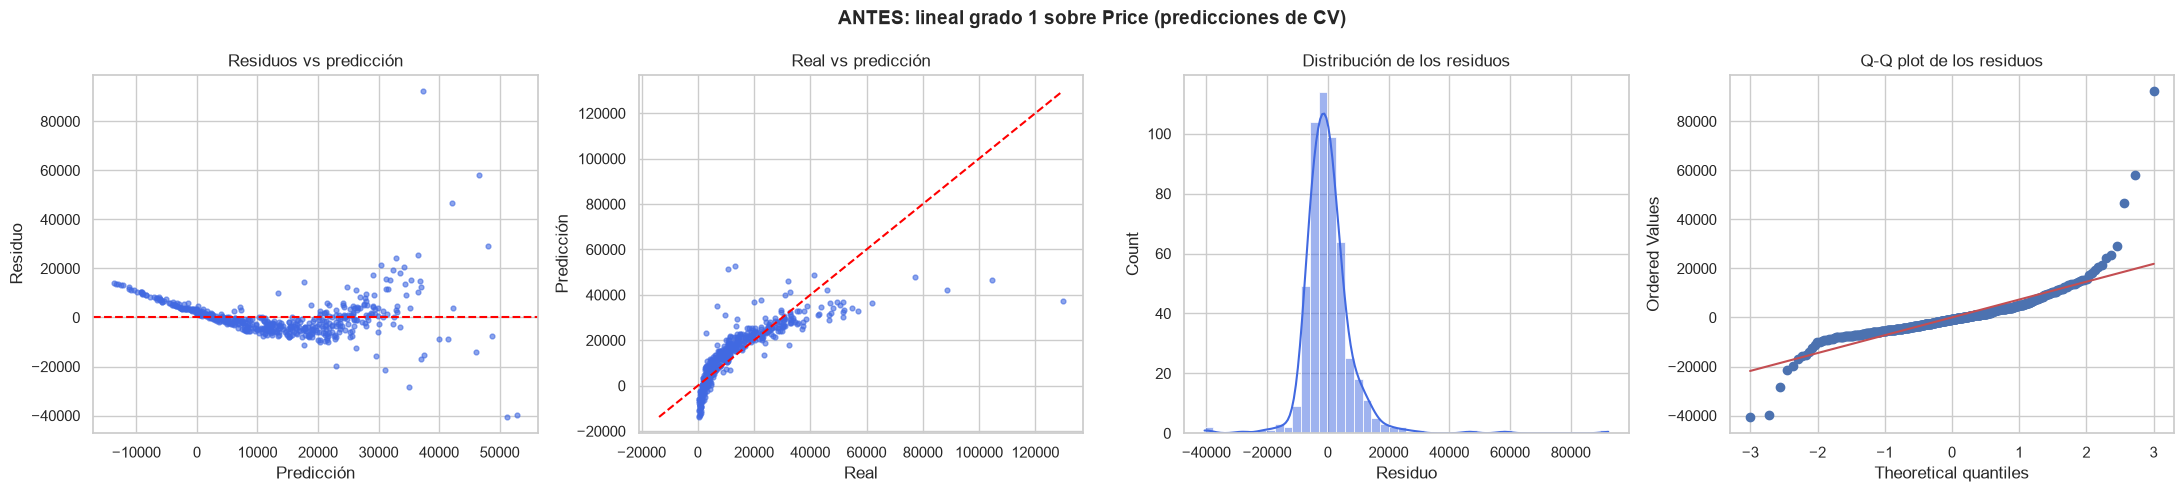

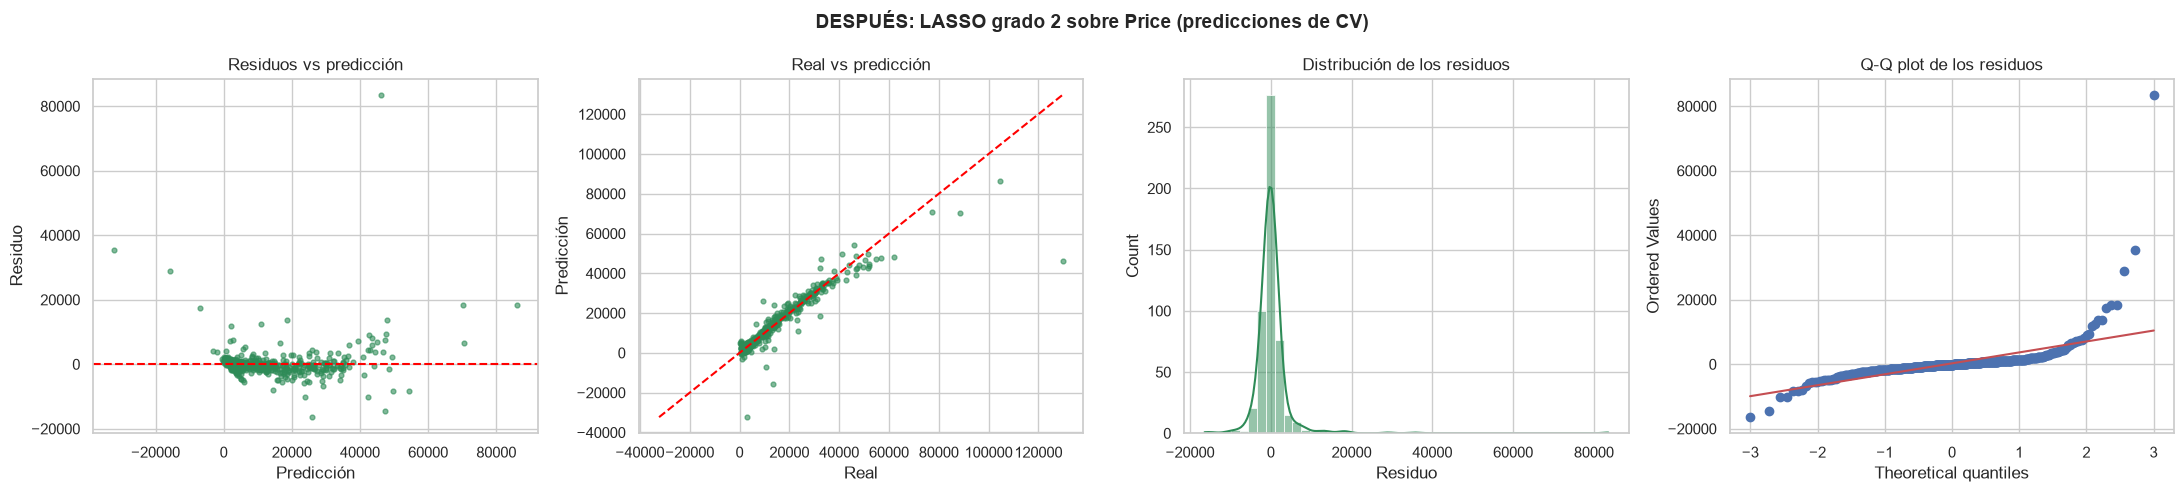

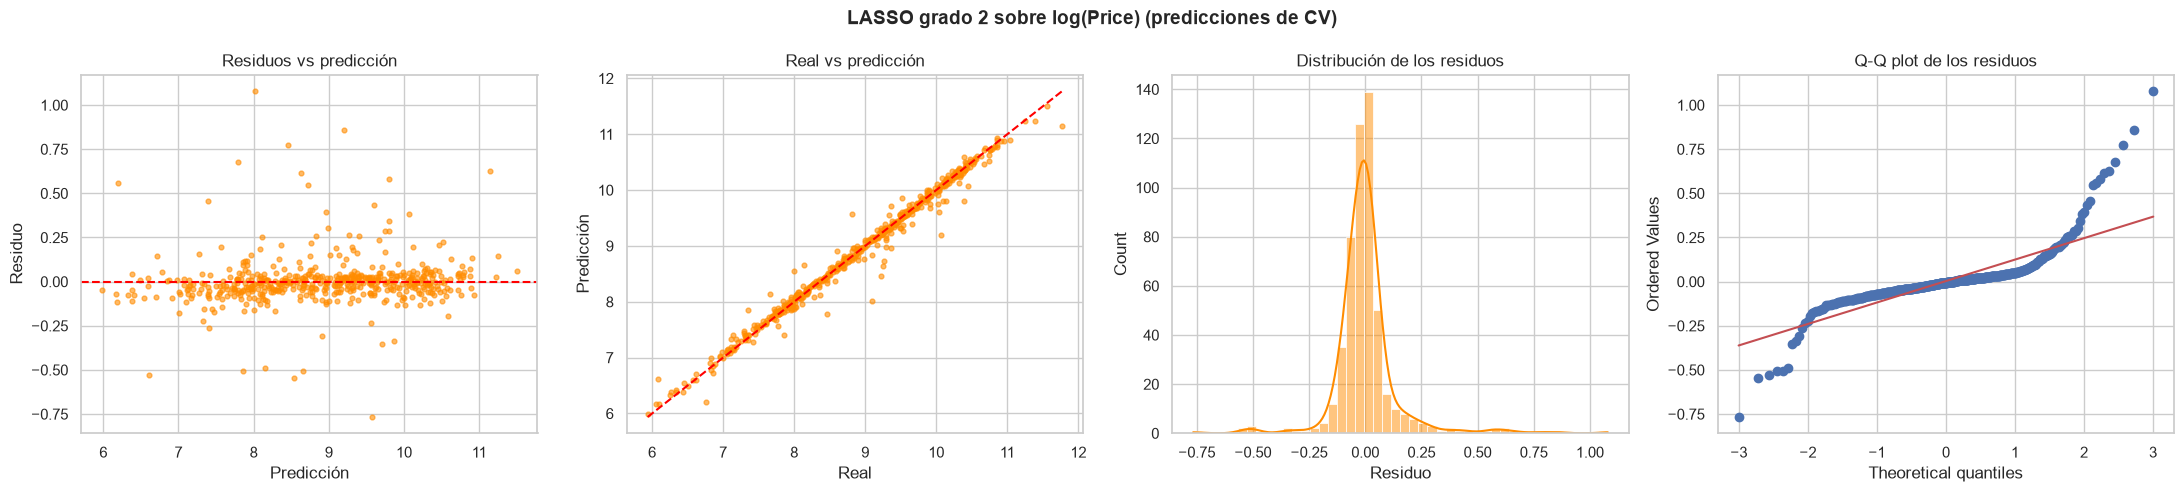

In [37]:
pred_cv_p_raw = cross_val_predict(lasso_p_raw.best_estimator_, P_train, Y_train, cv=cv)
pred_cv_p_log = np.log(cross_val_predict(lasso_p_log.best_estimator_, P_train, Y_train, cv=cv))
graficar_residuos(Y_train, pred_cv_raw, "ANTES: lineal grado 1 sobre Price (predicciones de CV)")
graficar_residuos(Y_train, pred_cv_p_raw, "DESPUÉS: LASSO grado 2 sobre Price (predicciones de CV)", color="seagreen")
graficar_residuos(Y_train_log, pred_cv_p_log, "LASSO grado 2 sobre log(Price) (predicciones de CV)", color="darkorange")

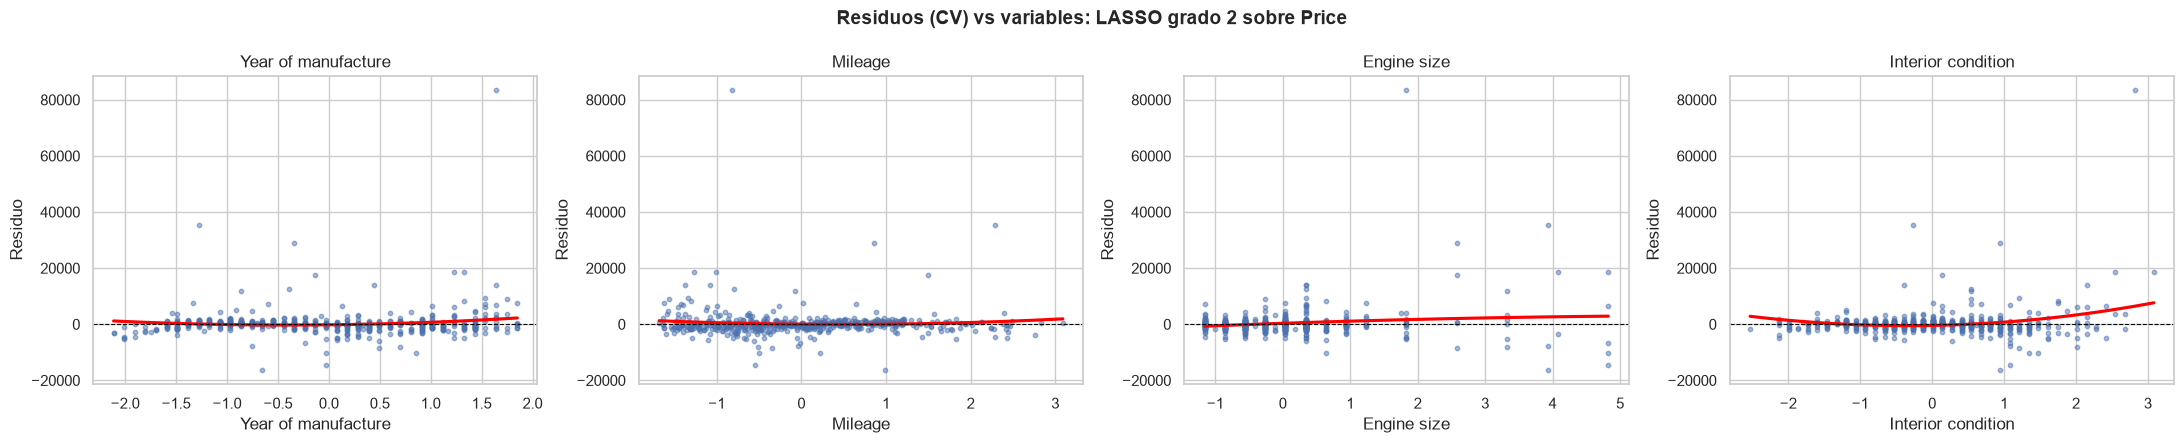

In [38]:
residuos_vs_variables(Y_train - pred_cv_p_raw, X_train, "Residuos (CV) vs variables: LASSO grado 2 sobre Price")

¿Se ha arreglado el problema de los residuos? (residuos de validación cruzada)

- Sobre `Price`: sí, en gran parte. La forma de U de los residuos frente a la predicción ha desaparecido, los residuos están centrados en 0 en todo el rango y su magnitud baja mucho. En "Real vs predicción" los puntos siguen la diagonal en lugar de una curva. Frente a `Year`, `Mileage` e `Interior condition` las parábolas rojas son ahora planas, cuando antes eran claramente curvas. Queda algo de heterocedasticidad (los residuos se abren en forma de embudo cuando el precio es alto) y algunas predicciones negativas para coches muy baratos. Además, al predecir con validación cruzada se ve que el coche más caro (unos 131.000 €) se predice muy por debajo (unos 46.000 €): cuando ese coche no está en el entrenamiento, no hay ningún otro parecido del que aprender. Son síntomas de que el error es proporcional al precio, algo que solo resuelve el logaritmo.
- Sobre `log(Price)`: los residuos eran ya buenos antes y siguen igual, con colas pesadas causadas por los mismos coches atípicos. Las interacciones no los explican, su precio debe depender de algo que no está en los datos.

LASSO grado 2 sobre Price: 115 de 313 variables con peso != 0 -> {'interacción': 97, 'original': 12, 'cuadrado': 6}
   Originales que elimina: ['Tires quality', 'Comfort level', 'Sound system quality', 'Model reviews score', 'Overall rating', 'Independent rating', 'Insurance cost', 'Maintenance cost', 'Model_911', 'Model_Focus', 'Model_M5', 'Model_Mondeo', 'Model_Passat', 'Model_Prius', 'Model_X3', 'Model_Z4']
LASSO grado 2 sobre log(Price): 52 de 313 variables con peso != 0 -> {'interacción': 36, 'original': 14, 'cuadrado': 2}
   Originales que elimina: ['Tires quality', 'Comfort level', 'Sound system quality', 'Model reviews score', 'Overall rating', 'Independent rating', 'Insurance cost', 'Maintenance cost', 'Model_Focus', 'Model_Mondeo', 'Model_Passat', 'Model_Prius', 'Model_X3', 'Model_Z4']


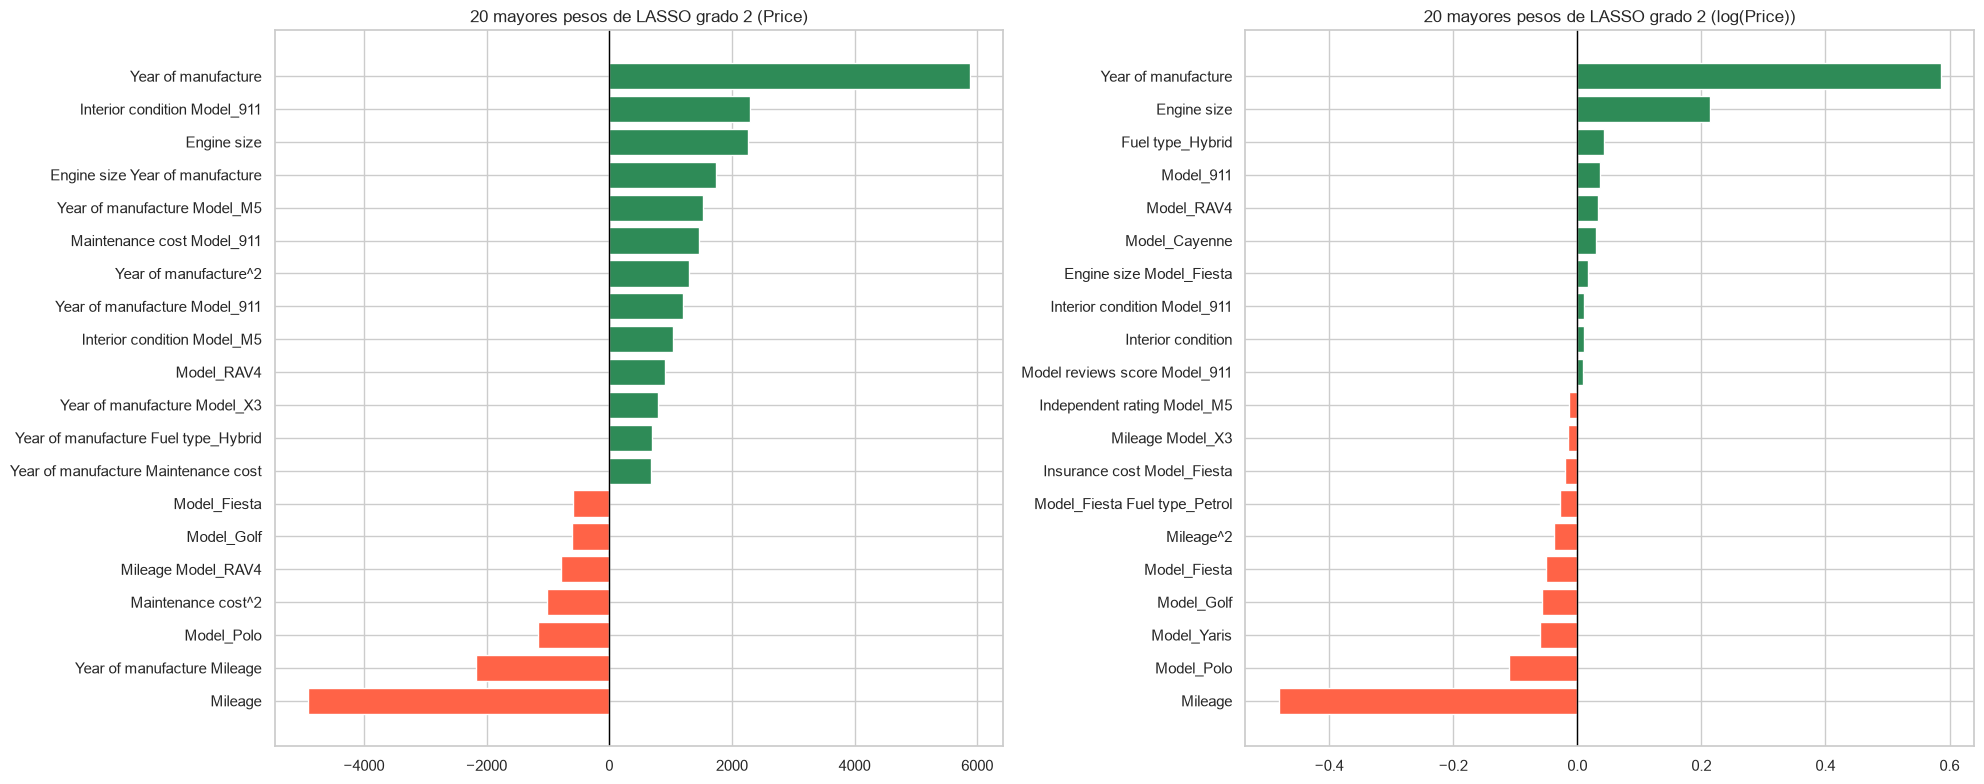

In [39]:
tipo = {nombre: "original" if pot.sum() == 1 else ("cuadrado" if pot.max() == 2 else "interacción") for nombre, pot in zip(poly.get_feature_names_out(), poly.powers_)}
for nombre, mod in [("Price", lasso_p_raw), ("log(Price)", lasso_p_log)]:
    coef = pd.Series(coefs(mod), index=P_train.columns)
    coef = coef[coef != 0]
    conteo = pd.Series([tipo[c] for c in coef.index]).value_counts().to_dict()
    print(f"LASSO grado 2 sobre {nombre}: {len(coef)} de {P_train.shape[1]} variables con peso != 0 -> {conteo}")
    print(f"   Originales que elimina: {[c for c in X_train.columns if c not in coef.index]}")

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, (nombre, mod) in zip(axes, [("Price", lasso_p_raw), ("log(Price)", lasso_p_log)]):
    coef = pd.Series(coefs(mod), index=P_train.columns)
    top = coef[coef.abs().sort_values(ascending=False).index[:20]].sort_values()
    ax.barh(top.index, top.values, color=["tomato" if v < 0 else "seagreen" for v in top])
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(f"20 mayores pesos de LASSO grado 2 ({nombre})")
plt.tight_layout()
plt.show()

- Sobre `Price`: se queda con 115 de 313 variables (37%): 12 originales, 97 interacciones y 6 cuadrados. Es un modelo complejo. Las variables más importantes forman un esquema claro:
  - Efectos principales de `Year of manufacture`, `Mileage` y `Engine size`.
  - `Year x Mileage` (−) y $\texttt{Year}^2$ (+): la depreciación no es lineal. El coche pierde más euros en los primeros años, tal como haría una curva exponencial
  - `Engine size × Year` (+): un motor grande vale más cuanto más nuevo es el coche
  - Interacciones con los modelos caros (`Interior condition × 911`, `Maintenance cost × 911`, `Year × 911`, `Year × M5`, `Interior condition × M5` etc..): en un coche caro, cada característica supone muchos más euros

Esto confirma la explicación que he dado en el apartado b), los efectos son multiplicativos (el mismo porcentaje de depreciación supone muchos más euros en un coche caro)
- Sobre `log(Price)`: se queda con solo 52 de 313 (17%): 14 originales, 36 interacciones y 2 cuadrados. Los pesos importantes son casi los mismos que en el modelo lineal: `Year`, `Mileage`, `Engine size`, híbrido y las dummy de los modelos. Las interacciones tienen pesos muy pequeños (< 0.03), salvo $\texttt{Mileage}^2$ (−0.04), que recoge la ligera curvatura en el km que vimos en los residuos del apartado b)

Comparado con el modelo log de grado 1 (28 variables, y 24 con alpha 1-SE), LASSO grado 2 es más complejo y menos interpretable, y su error de validación cruzada no es mejor.

# Conclusiones

Todos los modelos se han evaluado con el mismo criterio (MAE en euros), estimando su error de generalización con validación cruzada de 10 folds sobre train y usando el test solo para comprobar que no hay sobreajuste.

1. Preprocesado (a): `Inspection rating` se elimina por no tener varianza. `Insurance cost` es binaria. `Manufacturer` se elimina porque la marca se deduce del modelo, mantener las dos producía colinealidad perfecta. Los NaN se imputan con `KNNImputer` sobre variables estandarizadas, con el número de vecinos ($k = 2$) elegido por validación cruzada. En el PCA (con todas las variables estandarizadas), la dirección de antigüedad/kilometraje (PC1) ordena los precios (correlación 0.83 con `log(Price)`), mientras que la de mayor varianza (PC0, valoraciones) apenas está relacionada con el precio.
2. Regresión lineal (b): sobre el precio original el ajuste es pobre (MAE de CV de 5.028 ± 1.047 €, predicciones negativas, residuos en forma de U). Con `log(Price)` el MAE de CV baja a 978 ± 262 €, y el MAE de test (886 €) cae dentro de esa distribución, sin sobreajuste. Los efectos son porcentuales: unos -6% por año, -42% por cada 64.000 km, y diferencias de gama entre modelos.
3. Ridge y LASSO (c): con `alpha` elegido por CV la regularización óptima es nula, así que no mejoran el error porque el modelo lineal no sobreajusta, pero confirman qué variables importan. LASSO con la regla 1-SE (error equivalente) elimina valoraciones y modelos de gama media y conserva año, kilometraje, gama del modelo, motor y combustible. El precio de un coche se explica por lo que es y lo usado que está, no por las opiniones sobre él.
4. Interacciones (d): sobre `Price`, `PolynomialFeatures` de grado 2 corrige la forma de U de los residuos y baja el MAE de CV de unos 5.000 € a 2.004 € (LASSO), pero a costa de un modelo con 115 variables poco interpretables. Sobre `log(Price)` no aporta: LASSO grado 2 tiene un error de CV equivalente (993 €) pero más variable, y Ridge grado 2 empeora (1.866 €).

El mejor modelo es el lineal sobre `log(Price)`: tiene el menor error de validación cruzada (978 €), los modelos que le empatan estadísticamente son más complejos, y es fácil de interpretar. La transformación logarítmica resuelve de raíz el problema que las interacciones solo resuelven de forma aproximada.